> **Run All 한 번으로 최종 test까지 실행하도록 정리된 파일입니다.**  
> `RUN_PIPELINE_TO_FINAL_TEST=True`이면 v0·B2·v1·v2 재학습 → 누수 없는 validation 선택 → 선택 모델의 원본 test 1회 평가까지 자동 진행됩니다.  
> 기존 탐색과 기존 test 코드는 자동으로 꺼지며, 완료된 재학습 버전은 이어받습니다.

# 뉴스 문서 요약 프로젝트 - 검증 완료 통합 노트북

**1조 · `daekeun-ml/naver-news-summarization-ko` · seed 42**

이 노트북은 가이드 PDF의 17개 항목과 첨부 데이터의 중복 경우 **A-G**를 한 흐름에 담는다.
원본 노트북에서 발견된 실행/평가 문제도 고쳤다.

- 주 모델: **KoBART (`gogamza/kobart-base-v2`)** - 요약에 맞는 인코더-디코더 구조
- 비교 모델: **KoGPT2**(디코더 전용), **KoELECTRA**(인코더 전용·생성 불가)
- 핵심 평가: 한국어 공백 토큰 기준 **ROUGE-1/2/L F1**, 의미 보완용 **BERTScore-F1**
- 데이터 안전장치: A-D 완전 일치 + E-G 유사 중복, 그룹 스플릿, test 1회 잠금
- 8GB GPU 안전장치: 동적 패딩, micro-batch, gradient accumulation, AMP, gradient checkpointing

> **정직한 결과 원칙**: 첨부 노트북에는 학습 출력이 저장되어 있지 않다. 따라서 학습 모델 점수는
> 만들어 쓰지 않는다. 이 노트북이 실제 실행 결과를 `experiment_log.csv`와 `outputs/`에 기록한다.

## 실행 모드

1. `SMOKE`로 전 셀을 확인한다.
2. 제출용 권장값은 `BALANCED12H`, 10시간 안쪽은 `FAST10H`, 장시간 전체 비교는 `FULL`이다.
3. validation으로 모든 선택을 끝낸 뒤에만 `RUN_FINAL_TEST=True`로 바꿔 test를 1회 평가한다.


## 0. Windows + RTX 50 시리즈 환경

PowerShell에서 이 노트북 폴더로 이동한 뒤 한 번만 실행한다.

```powershell
.\setup_windows.ps1
```

수동 설치가 필요하면:

```powershell
uv venv --python 3.11 .venv
uv pip install --python .venv\Scripts\python.exe torch==2.7.1 torchvision==0.22.1 --index-url https://download.pytorch.org/whl/cu128
uv pip install --python .venv\Scripts\python.exe -r requirements-windows.txt
.venv\Scripts\python.exe -m ipykernel install --user --name news-summary-cu128 --display-name "Python 3.11 (news summary, CUDA 12.8)"
```

커널은 **Python 3.11 (news summary, CUDA 12.8)** 을 선택한다. `torchtext`는 이 환경에서 사용하지 않는다.
레거시 실습이 꼭 필요할 때만 `requirements-torchtext.txt`로 별도 CPU 환경을 만든다.


In [1]:
# 실행 설정 - 이 셀에서는 아래 한 줄만 확인하면 된다.
RUN_PIPELINE_TO_FINAL_TEST = True  # True: v0/B2/v1/v2 재학습 → validation 선택 → test 1회

RUN_MODE = "BALANCED12H"
RUN_FUZZY_AUDIT = True
RUN_TOKENIZER_DEMOS = True
RUN_KONLPY_DEMO = False
RETRAIN_RESUME_EXISTING = True     # 완료된 버전은 재사용하여 중단 후 이어서 실행
RUN_REQUESTED_BERTSCORE = False    # 필요할 때만 True; test 시간이 약 15~30분 증가

# 아래 값은 위의 마스터 스위치에서 자동 결정한다. 직접 바꾸지 않는다.
RUN_REQUESTED_VERSION_RETRAINING = RUN_PIPELINE_TO_FINAL_TEST
RUN_SELECTED_TEST_ONCE = RUN_PIPELINE_TO_FINAL_TEST
SELECTED_TEST_CONFIRM = "TEST는_최종_1회" if RUN_PIPELINE_TO_FINAL_TEST else ""

# 기존 탐색·기존 test 경로는 새 파이프라인과 동시에 실행하지 않는다.
RUN_MODEL_EXPERIMENTS = False
RUN_STRUCTURE_COMPARISON = False
RUN_BERTSCORE = False
RUN_FINAL_TEST = False

PRESETS = {
    "SMOKE": dict(
        train_n=64, valid_n=16, epochs=1, max_source=512, max_target=128,
        micro_batch=1, effective_batch=4,
        lr_grid=[3e-5], epoch_grid=[1], length_grid=[512], batch_grid=[4],
        generation_n=8, fuzzy_chunk=750,
    ),
    "FAST10H": dict(
        # RTX 5060 Laptop에서 최종 test까지 약 6~9시간 목표.
        # 탐색/비교는 1,000건으로 줄이되 최종 모델은 전체 strict train으로 학습한다.
        train_n=1000, valid_n=200, epochs=2, max_source=512, max_target=160,
        micro_batch=2, effective_batch=8,
        lr_grid=[1e-5, 3e-5, 5e-5], epoch_grid=[1, 2],
        length_grid=[512], batch_grid=[4, 8],
        generation_n=100, fuzzy_chunk=750, comparison_epochs=1,
    ),
    "BALANCED12H": dict(
        # RTX 5060 Laptop에서 최종 test까지 약 10~14시간 목표.
        # 모든 주요 후보를 비교하되 최종 전체 학습은 512토큰/2epoch로 고정한다.
        train_n=1500, valid_n=300, epochs=2, max_source=512, max_target=160,
        micro_batch=2, effective_batch=8,
        lr_grid=[1e-5, 3e-5, 5e-5], epoch_grid=[1, 2, 3],
        length_grid=[512, 1024], batch_grid=[4, 8, 16],
        generation_n=150, fuzzy_chunk=750, comparison_epochs=1,
        force_final_epochs=2, force_final_max_source=512,
    ),
    "FULL": dict(
        # 탐색은 3,000건, 최종 확정 모델만 아래 12장에서 전체 strict train으로 학습
        train_n=3000, valid_n=600, epochs=3, max_source=512, max_target=160,
        micro_batch=2, effective_batch=8,
        lr_grid=[1e-5, 3e-5, 5e-5], epoch_grid=[1, 3, 5],
        length_grid=[512, 1024], batch_grid=[4, 8, 16],
        generation_n=300, fuzzy_chunk=750,
    ),
}
if RUN_MODE not in PRESETS:
    raise ValueError("RUN_MODE는 'SMOKE', 'FAST10H', 'BALANCED12H', 'FULL' 중 하나여야 합니다.")
CFG = PRESETS[RUN_MODE]

from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations
import contextlib, datetime, gc, hashlib, importlib.metadata as im
import json, math, os, platform, random, re, time, unicodedata, warnings

# setup_windows.ps1에서 필요한 모델을 모두 미리 받는다. 장시간 학습 중
# 네트워크/허브 상태 때문에 중단되지 않도록 노트북은 로컬 캐시만 사용한다.
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
_root_candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next((candidate for candidate in _root_candidates
             if (candidate / "data" / "train.csv").exists()), Path.cwd())
DATA_DIR = ROOT / "data"
OUT_DIR = ROOT / "outputs"
VERSION_DIR = OUT_DIR / "versions"
MODEL_DIR = ROOT / "models"
for directory in (OUT_DIR, VERSION_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
windows_font = Path(os.environ.get("WINDIR", r"C:\Windows")) / "Fonts" / "malgun.ttf"
if windows_font.exists():
    matplotlib.font_manager.fontManager.addfont(str(windows_font))
    matplotlib.rcParams["font.family"] = "Malgun Gothic"
else:
    for font_name in ("AppleGothic", "NanumGothic", "Noto Sans CJK KR"):
        if any(font_name in item.name for item in matplotlib.font_manager.fontManager.ttflist):
            matplotlib.rcParams["font.family"] = font_name
            break
matplotlib.rcParams["axes.unicode_minus"] = False

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except Exception:
        pass

def log_experiment(name, config, scores, note=""):
    csv_path = OUT_DIR / "experiment_log.csv"
    jsonl_path = OUT_DIR / "experiment_log.jsonl"
    row = {
        "time": datetime.datetime.now().isoformat(timespec="minutes"),
        "experiment": name,
        "run_mode": RUN_MODE,
        **config,
        **scores,
        "note": note,
    }
    # 실험마다 설정/지표 열이 달라 CSV에 행을 바로 append하면 열 수가 깨진다.
    # JSONL을 원본 로그로 append한 뒤 전체 열의 합집합으로 CSV를 다시 만든다.
    with jsonl_path.open("a", encoding="utf-8") as stream:
        stream.write(json.dumps(row, ensure_ascii=False, default=str) + "\n")
    records = []
    with jsonl_path.open(encoding="utf-8") as stream:
        for line in stream:
            if line.strip():
                records.append(json.loads(line))
    pd.json_normalize(records, sep=".").to_csv(
        csv_path, index=False, encoding="utf-8-sig")

seed_everything()
print("RUN_MODE:", RUN_MODE, "| SEED:", SEED)
print("DATA_DIR:", DATA_DIR.resolve())


RUN_MODE: BALANCED12H | SEED: 42
DATA_DIR: C:\news_summary_balanced\최종본_BALANCED12H_VERIFIED_패키지\data


In [2]:
# 환경 사전점검 - 잘못된 커널에서 긴 학습을 시작하지 않게 막는다.
def package_version(name):
    try:
        return im.version(name)
    except im.PackageNotFoundError:
        return "not installed"

versions = pd.Series({
    name: package_version(name)
    for name in ["torch", "torchvision", "transformers", "tokenizers", "datasets",
                 "accelerate", "pandas", "scikit-learn", "rouge-score", "bert-score"]
}, name="version")
display(versions.to_frame())

try:
    import torch
    TORCH_OK = tuple(map(int, torch.__version__.split("+")[0].split(".")[:2])) >= (2, 7)
    CUDA_OK = torch.cuda.is_available()
    DEVICE = "cuda" if CUDA_OK else "cpu"
    if CUDA_OK:
        gpu = torch.cuda.get_device_properties(0)
        GPU_NAME = gpu.name
        GPU_GB = gpu.total_memory / 1024**3
        CAPABILITY = torch.cuda.get_device_capability(0)
        USE_AMP = True
        AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        print(f"GPU: {GPU_NAME} | VRAM {GPU_GB:.1f} GiB | compute {CAPABILITY}")
        print("PyTorch:", torch.__version__, "| CUDA build:", torch.version.cuda,
              "| AMP:", str(AMP_DTYPE).replace("torch.", ""))
        if CAPABILITY[0] >= 12 and not TORCH_OK:
            raise RuntimeError("RTX 50 시리즈는 torch 2.7+ CUDA 12.8 빌드가 필요합니다.")
        cuda_build = tuple(map(int, (torch.version.cuda or "0.0").split(".")[:2]))
        if CAPABILITY[0] >= 12 and cuda_build < (12, 8):
            raise RuntimeError("RTX 50 시리즈는 CUDA 12.8 이상 PyTorch 빌드가 필요합니다.")
    else:
        GPU_NAME, GPU_GB, CAPABILITY, USE_AMP, AMP_DTYPE = "CPU", 0.0, None, False, None
        warnings.warn("CUDA GPU가 없어 모델 학습 셀을 자동으로 건너뜁니다.")
except ImportError:
    TORCH_OK = CUDA_OK = USE_AMP = False
    DEVICE, GPU_NAME, GPU_GB, CAPABILITY, AMP_DTYPE = "cpu", "torch 없음", 0.0, None, None
    warnings.warn("torch가 없습니다. 데이터 분석 셀만 실행합니다.")

MODEL_READY = bool(TORCH_OK and CUDA_OK)
if RUN_MODEL_EXPERIMENTS and not MODEL_READY:
    RUN_MODEL_EXPERIMENTS = False
    RUN_STRUCTURE_COMPARISON = False
    print("RUN_MODEL_EXPERIMENTS=False (호환 CUDA 환경이 아님)")

print("Python:", platform.python_version(), "| Device:", DEVICE)


,version
torch,2.7.1+cu128
torchvision,0.22.1+cu128
transformers,4.44.2
tokenizers,0.19.1
datasets,2.21.0
accelerate,0.33.0
pandas,2.2.2
scikit-learn,1.5.2
rouge-score,0.1.2
bert-score,0.3.13


GPU: NVIDIA GeForce RTX 5060 Laptop GPU | VRAM 7.9 GiB | compute (12, 0)
PyTorch: 2.7.1+cu128 | CUDA build: 12.8 | AMP: bfloat16
Python: 3.11.15 | Device: cuda


## 1. 교수님 요구사항과 전체 파이프라인

각 단계는 **선택 → 근거 → 비교 → 로그** 순서로 남긴다.

`데이터 확인 → 전처리/중복 진단 → 누수 없는 스플릿 → 토큰화 → 임베딩 → 구조 비교 → 전이학습 →
하이퍼파라미터 → 디코딩 → validation 확정 → test 1회 → 오류분석/시각화`

이 노트북이 만드는 핵심 산출물은 `experiment_log.csv`, A-G 교차표, 전처리/스플릿 통계,
validation 비교표, 최종 test 예측, `error_analysis.xlsx`, 오류 시각화 4종이다.


## 2. 데이터 불러오기와 무결성 확인

CSV를 우선 사용해 네트워크와 원본 버전 변화의 영향을 없앤다. 필수 열, 행 수, 결측치와 SHA-256을 확인한다.
전처리는 원문 의미를 바꾸지 않는 **NFKC + 공백 정리**만 사용하며, 원본 열은 보존한다.


In [3]:
REQUIRED_COLUMNS = ["date", "category", "press", "title", "document", "link", "summary"]
EXPECTED_ROWS = {"train": 22194, "validation": 2466, "test": 2740}

def sha256(path, block_size=1024 * 1024):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()

def normalize_text(value):
    text = unicodedata.normalize("NFKC", str(value))
    return re.sub(r"\s+", " ", text).strip()

missing_files = [name for name in EXPECTED_ROWS if not (DATA_DIR / f"{name}.csv").exists()]
if missing_files:
    raise FileNotFoundError(f"data 폴더에 CSV가 없습니다: {missing_files}")

splits = {}
fingerprints = []
for split_name, expected in EXPECTED_ROWS.items():
    path = DATA_DIR / f"{split_name}.csv"
    frame = pd.read_csv(path)
    missing = sorted(set(REQUIRED_COLUMNS) - set(frame.columns))
    if missing:
        raise ValueError(f"{split_name}: 필수 열 누락 {missing}")
    if len(frame) != expected:
        warnings.warn(f"{split_name}: 예상 {expected:,}행, 실제 {len(frame):,}행")
    frame = frame[REQUIRED_COLUMNS].copy()
    frame["split"] = split_name
    frame["source_row"] = np.arange(len(frame), dtype=np.int64)
    splits[split_name] = frame
    fingerprints.append({"split": split_name, "rows": len(frame), "sha256": sha256(path)})

full = pd.concat(splits.values(), ignore_index=True)
full["row_id"] = np.arange(len(full), dtype=np.int64)
for column in ("title", "document", "summary"):
    full[f"norm_{column}"] = full[column].map(normalize_text)

assert full[REQUIRED_COLUMNS].isna().sum().sum() == 0, "필수 열에 결측치가 있습니다."
assert full["row_id"].is_unique
display(pd.DataFrame(fingerprints))
print(f"총 {len(full):,}행 | 범주 {full.category.value_counts().to_dict()} | "
      f"언론사 {full.press.nunique()}곳 | 날짜 {full.date.astype(str).str[:10].nunique()}일")


,split,rows,sha256
0,train,22194,039a89adedfb305208475bc2c65e63769b021af5bb6f27...
1,validation,2466,c6600c6e2528688bdc12b34af170f2d6bfb8251d0d4478...
2,test,2740,369ddb4e1eb791efa6e2a074ca3ee4a727bfa7d4ee9f6f...


총 27,400행 | 범주 {'economy': 21049, 'IT과학': 6351} | 언론사 81곳 | 날짜 10일


,split,rows,doc_min,doc_median,doc_p95,doc_max,summary_min,summary_median,summary_p95,summary_max,mean_compression_doc_div_summary
0,train,22194,29,854.0,2306.35,16889,59,171.0,284.0,1838,6.02
1,validation,2466,48,864.5,2326.75,15384,60,171.0,276.0,1639,6.19
2,test,2740,49,861.0,2344.05,9221,66,170.0,283.0,1838,5.98


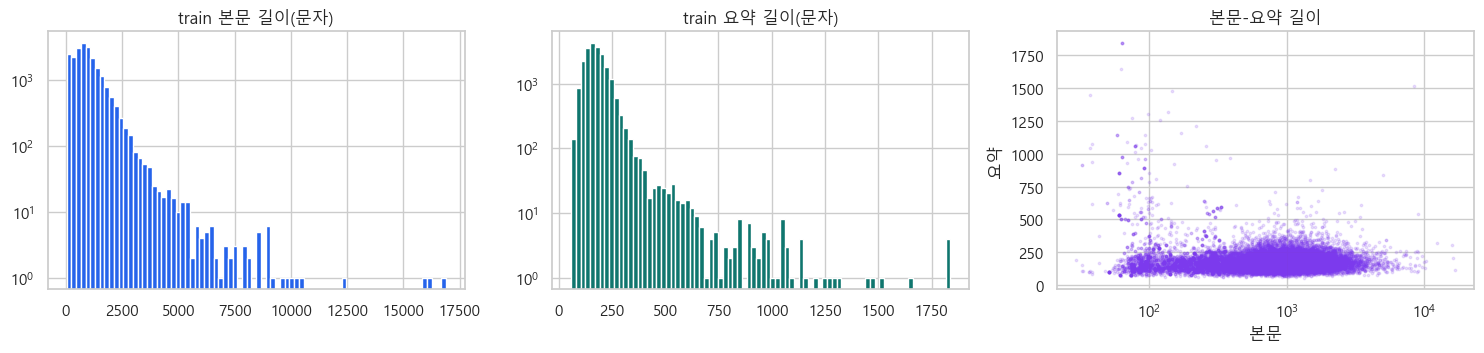

In [4]:
# 문자 길이와 압축률
profile_rows = []
for split_name, frame in splits.items():
    doc_len = frame.document.astype(str).str.len()
    sum_len = frame.summary.astype(str).str.len()
    profile_rows.append({
        "split": split_name, "rows": len(frame),
        "doc_min": int(doc_len.min()), "doc_median": float(doc_len.median()),
        "doc_p95": float(doc_len.quantile(.95)), "doc_max": int(doc_len.max()),
        "summary_min": int(sum_len.min()), "summary_median": float(sum_len.median()),
        "summary_p95": float(sum_len.quantile(.95)), "summary_max": int(sum_len.max()),
        "mean_compression_doc_div_summary": float((doc_len / sum_len.clip(lower=1)).mean()),
    })
profile = pd.DataFrame(profile_rows)
profile.to_csv(OUT_DIR / "data_profile.csv", index=False, encoding="utf-8-sig")
display(profile.round(2))

train_plot = splits["train"].copy()
train_plot["doc_chars"] = train_plot.document.str.len()
train_plot["summary_chars"] = train_plot.summary.str.len()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.7))
axes[0].hist(train_plot.doc_chars, bins=80, color="#2563eb"); axes[0].set_yscale("log")
axes[0].set_title("train 본문 길이(문자)")
axes[1].hist(train_plot.summary_chars, bins=80, color="#0f766e"); axes[1].set_yscale("log")
axes[1].set_title("train 요약 길이(문자)")
axes[2].scatter(train_plot.doc_chars, train_plot.summary_chars, s=3, alpha=.15, color="#7c3aed")
axes[2].set_xscale("log"); axes[2].set_xlabel("본문"); axes[2].set_ylabel("요약")
axes[2].set_title("본문-요약 길이")
plt.tight_layout(); plt.savefig(OUT_DIR / "01_length_distribution.png", dpi=150); plt.show()


### 전처리 원칙

- 모델 입력: NFKC 정규화와 연속 공백 정리만 적용한다. 숫자·문장부호·고유명사는 보존한다.
- 삭제가 아닌 **의심 플래그**를 먼저 만든다. 반복, 본문-요약 단어 겹침, 비정상 길이는 자동 확정 오류가 아니다.
- 전처리 효과는 같은 validation으로 원본/정제 학습을 비교한다.
- test 문장이나 정답을 보면서 임계값·모델·디코딩을 선택하지 않는다.


In [5]:
def has_repeat(text, n=4, minimum_count=3):
    words = str(text).split()
    if len(words) < n:
        return False
    counts = Counter(tuple(words[i:i+n]) for i in range(len(words) - n + 1))
    return max(counts.values(), default=0) >= minimum_count

def overlap_ratio(document, summary):
    document_tokens = set(str(document).split())
    summary_tokens = str(summary).split()
    return sum(token in document_tokens for token in summary_tokens) / max(len(summary_tokens), 1)

full["doc_chars"] = full.document.str.len()
full["summary_chars"] = full.summary.str.len()
full["summary_doc_ratio"] = full.summary_chars / full.doc_chars.clip(lower=1)
full["repeat_flag"] = full.summary.map(has_repeat)
full["overlap"] = full.apply(lambda row: overlap_ratio(row.document, row.summary), axis=1)
full["suspect_low_overlap"] = full.overlap < 0.30
full["suspect_length"] = full.summary_doc_ratio > 1.0
# 자동 삭제는 더 보수적으로: 강한 반복, 겹침 0.15 미만, 요약이 본문의 2배 초과 중 하나
full["high_confidence_noise"] = (
    full.repeat_flag | (full.overlap < 0.15) | (full.summary_doc_ratio > 2.0)
)

noise_stats = (full.groupby("split")
    .agg(rows=("row_id", "size"), repeated=("repeat_flag", "sum"),
         overlap_lt_030=("suspect_low_overlap", "sum"),
         summary_longer=("suspect_length", "sum"),
         high_confidence_noise=("high_confidence_noise", "sum"))
    .reset_index())
noise_stats.to_csv(OUT_DIR / "noise_flags.csv", index=False, encoding="utf-8-sig")
display(noise_stats)

review_noise = pd.concat([
    full.nsmallest(30, "overlap"),
    full[full.repeat_flag].head(30),
    full.nlargest(30, "summary_doc_ratio"),
]).drop_duplicates("row_id")
review_noise[REQUIRED_COLUMNS + ["split", "row_id", "overlap", "repeat_flag",
                                 "summary_doc_ratio"]].to_csv(
    OUT_DIR / "noise_review_candidates.csv", index=False, encoding="utf-8-sig")
print("자동 플래그는 의심 후보입니다. 최종 삭제 판단은 noise_review_candidates.csv를 읽고 확정합니다.")


,split,rows,repeated,overlap_lt_030,summary_longer,high_confidence_noise
0,test,2740,130,0,195,135
1,train,22194,1091,5,1739,1157
2,validation,2466,120,0,198,125


자동 플래그는 의심 후보입니다. 최종 삭제 판단은 noise_review_candidates.csv를 읽고 확정합니다.


## 3. 중복·누수 A-G 전수 진단

|유형|본문|요약|제목|의미|
|---|---|---|---|---|
|A|동일|동일|무관|행 전체 복사(링크만 다를 수 있음)|
|B|동일|다름|무관|같은 기사에 다른 정답|
|C|다름|동일|무관|다른 기사에 같은 정답|
|D|다름|다름|동일|제목만 같음|
|E|유사|유사|무관|거의 복사본|
|F|유사|다름|무관|비슷한 기사, 다른 요약|
|G|다름|유사|무관|다른 기사, 비슷한 요약|

A-D는 문자열의 완전 일치 층, E-G는 TF-IDF 코사인 유사도 층이다. 제목은 E-G에서 무관하므로
**D와 E/F/G는 동시에 성립할 수 있다.** 이를 억지로 하나의 배타 클래스에 넣지 않고 두 플래그를 보존한다.
위치는 `train 내부`, `train↔validation`, `train↔test`, `validation↔test` 4칸을 본표로 쓰고,
validation/test 내부는 참고표로 분리한다.


In [6]:
def text_hash(value):
    return hashlib.sha256(normalize_text(value).encode("utf-8")).hexdigest()[:24]

for column in ("document", "summary", "title"):
    full[f"key_{column}"] = full[column].map(text_hash)

def enumerate_exact_pairs(frame):
    doc = frame.key_document.to_numpy()
    summary = frame.key_summary.to_numpy()
    title = frame.key_title.to_numpy()
    row_ids = frame.row_id.to_numpy()
    groups = defaultdict(list)
    for column in ("key_document", "key_summary", "key_title"):
        for key, indexes in frame.groupby(column, sort=False).indices.items():
            if len(indexes) > 1:
                groups[(column, key)] = indexes
    seen, rows = set(), []
    for indexes in groups.values():
        for left, right in combinations(sorted(indexes), 2):
            pair = (int(row_ids[left]), int(row_ids[right]))
            if pair in seen:
                continue
            seen.add(pair)
            same_doc = doc[left] == doc[right]
            same_summary = summary[left] == summary[right]
            same_title = title[left] == title[right]
            if same_doc and same_summary:
                case = "A"
            elif same_doc:
                case = "B"
            elif same_summary:
                case = "C"
            elif same_title:
                case = "D"
            else:
                continue
            rows.append((pair[0], pair[1], case))
    return pd.DataFrame(rows, columns=["row_a", "row_b", "case"])

split_of = full.set_index("row_id").split.to_dict()
def pair_position(a, b):
    left, right = split_of[int(a)], split_of[int(b)]
    if left == right:
        return f"{left} 내부"
    return {
        ("train", "validation"): "train↔validation",
        ("test", "train"): "train↔test",
        ("test", "validation"): "validation↔test",
    }[tuple(sorted((left, right)))]

exact_pairs = enumerate_exact_pairs(full)
exact_pairs["position"] = [pair_position(a, b) for a, b in zip(exact_pairs.row_a, exact_pairs.row_b)]
exact_pairs.to_csv(OUT_DIR / "exact_pairs_ABCD.csv", index=False, encoding="utf-8-sig")
exact_table = pd.crosstab(exact_pairs.case, exact_pairs.position).reindex(index=list("ABCD"), fill_value=0)
exact_table["전체"] = exact_table.sum(axis=1)
print("A-D 완전 일치 쌍 (쌍 수이며, 행 수와 다름)")
display(exact_table.fillna(0).astype(int))


A-D 완전 일치 쌍 (쌍 수이며, 행 수와 다름)


position,test 내부,train 내부,train↔test,train↔validation,validation 내부,validation↔test,전체
case,,,,,,,
A,54,5077,1168,1256,91,156,7802
B,0,0,0,0,0,0,0
C,3,128,36,31,2,5,205
D,16,1271,268,338,21,49,1963


In [7]:
# E-G: 본문과 요약을 각각 TF-IDF(1-2 word n-gram)로 벡터화하고 코사인 유사도를 계산한다.
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize

CANDIDATE_THRESHOLD = 0.50
FUZZY_THRESHOLD = 0.85  # 0.50~0.95 민감도 표와 실제 사례를 함께 보고 결정
EXACT_SIM = 0.9999

def candidate_pairs(matrix, threshold=CANDIDATE_THRESHOLD, chunk=CFG["fuzzy_chunk"]):
    out_i, out_j, out_s = [], [], []
    n_rows = matrix.shape[0]
    for start in range(0, n_rows, chunk):
        stop = min(start + chunk, n_rows)
        similarities = (matrix[start:stop] @ matrix.T).toarray().astype(np.float32)
        for local_row in range(stop - start):
            similarities[local_row, :start + local_row + 1] = 0.0
        local_i, local_j = np.nonzero(similarities >= threshold)
        out_i.append(local_i + start); out_j.append(local_j); out_s.append(similarities[local_i, local_j])
    return np.concatenate(out_i), np.concatenate(out_j), np.concatenate(out_s)

def fill_similarity(matrix, left, right):
    return np.asarray(matrix[left].multiply(matrix[right]).sum(axis=1)).ravel()

fuzzy_cache = OUT_DIR / "fuzzy_candidates.parquet"
if RUN_FUZZY_AUDIT or not fuzzy_cache.exists():
    vec_kwargs = dict(analyzer="word", ngram_range=(1, 2), min_df=2,
                      max_features=200_000, sublinear_tf=True, dtype=np.float32)
    started = time.perf_counter()
    X_doc = normalize(TfidfVectorizer(**vec_kwargs).fit_transform(full.document.astype(str)))
    X_sum = normalize(TfidfVectorizer(**vec_kwargs).fit_transform(full.summary.astype(str)))
    di, dj, ds = candidate_pairs(X_doc)
    si, sj, ss = candidate_pairs(X_sum)
    candidates = (pd.concat([
        pd.DataFrame({"row_a": di, "row_b": dj, "doc_sim": ds.astype(float)}),
        pd.DataFrame({"row_a": si, "row_b": sj, "sum_sim": ss.astype(float)}),
    ], ignore_index=True).groupby(["row_a", "row_b"], as_index=False).first())
    need_doc = candidates.doc_sim.isna(); need_sum = candidates.sum_sim.isna()
    if need_doc.any():
        candidates.loc[need_doc, "doc_sim"] = fill_similarity(
            X_doc, candidates.loc[need_doc, "row_a"].to_numpy(),
            candidates.loc[need_doc, "row_b"].to_numpy())
    if need_sum.any():
        candidates.loc[need_sum, "sum_sim"] = fill_similarity(
            X_sum, candidates.loc[need_sum, "row_a"].to_numpy(),
            candidates.loc[need_sum, "row_b"].to_numpy())
    try:
        candidates.to_parquet(fuzzy_cache, index=False)
    except Exception:
        candidates.to_csv(OUT_DIR / "fuzzy_candidates.csv", index=False, encoding="utf-8-sig")
    print(f"유사 후보 {len(candidates):,}쌍 | {time.perf_counter()-started:.1f}초")
elif fuzzy_cache.exists():
    candidates = pd.read_parquet(fuzzy_cache)

def fuzzy_labels(frame, threshold):
    d, s = frame.doc_sim.to_numpy(), frame.sum_sim.to_numpy()
    labels = np.full(len(frame), "", dtype=object)
    labels[(d >= threshold) & (s >= threshold) & ~((d >= EXACT_SIM) & (s >= EXACT_SIM))] = "E"
    labels[(d >= threshold) & (s < threshold)] = "F"
    # C(요약 완전 동일)는 정확층에서 이미 보고하므로 G에서 제외
    labels[(d < threshold) & (s >= threshold) & (s < EXACT_SIM)] = "G"
    return labels

candidates["fuzzy_case"] = fuzzy_labels(candidates, FUZZY_THRESHOLD)
fuzzy_pairs = candidates[candidates.fuzzy_case != ""].copy()
fuzzy_pairs["position"] = [pair_position(a, b) for a, b in zip(fuzzy_pairs.row_a, fuzzy_pairs.row_b)]
fuzzy_pairs.to_csv(OUT_DIR / "fuzzy_pairs_EFG.csv", index=False, encoding="utf-8-sig")

sweep_rows = []
for threshold in (.50, .60, .70, .80, .85, .90, .95):
    labels = pd.Series(fuzzy_labels(candidates, threshold)).value_counts()
    sweep_rows.append({"threshold": threshold, **{case: int(labels.get(case, 0)) for case in "EFG"}})
fuzzy_sweep = pd.DataFrame(sweep_rows)
fuzzy_sweep.to_csv(OUT_DIR / "fuzzy_threshold_sweep.csv", index=False, encoding="utf-8-sig")
display(fuzzy_sweep)
display(pd.crosstab(fuzzy_pairs.fuzzy_case, fuzzy_pairs.position))

# 임계값은 숫자만 보고 고르지 않는다. E/F/G별 실제 쌍을 검토용 CSV로 저장한다.
fuzzy_review_parts = []
full_by_id = full.set_index("row_id")
for case_name in "EFG":
    case_rows = fuzzy_pairs[fuzzy_pairs.fuzzy_case.eq(case_name)]
    if case_rows.empty:
        continue
    sampled = case_rows.sample(min(10, len(case_rows)), random_state=SEED)
    for pair in sampled.itertuples():
        left = full_by_id.loc[int(pair.row_a)]
        right = full_by_id.loc[int(pair.row_b)]
        fuzzy_review_parts.append({
            "case": case_name, "doc_sim": pair.doc_sim, "sum_sim": pair.sum_sim,
            "position": pair.position, "row_a": pair.row_a, "row_b": pair.row_b,
            "title_a": left.title, "title_b": right.title,
            "document_a": left.document, "document_b": right.document,
            "summary_a": left.summary, "summary_b": right.summary,
        })
fuzzy_review = pd.DataFrame(fuzzy_review_parts)
fuzzy_review.to_csv(OUT_DIR / "fuzzy_pair_manual_review.csv", index=False, encoding="utf-8-sig")
print("임계 0.85 수동 확인용 E/F/G 각 최대 10쌍 저장: fuzzy_pair_manual_review.csv")


유사 후보 68,947쌍 | 47.9초


,threshold,E,F,G
0,0.50,16836,41217,3087
1,0.60,9479,28815,1730
2,0.70,4755,20178,1124
3,0.80,2169,11320,570
4,0.85,1422,7643,444
5,0.90,806,4145,268
6,0.95,245,1518,166


position,test 내부,train 내부,train↔test,train↔validation,validation 내부,validation↔test
fuzzy_case,,,,,,
E,26,861,265,226,11,33
F,83,5048,1239,1081,51,141
G,5,280,77,62,8,12


임계 0.85 수동 확인용 E/F/G 각 최대 10쌍 저장: fuzzy_pair_manual_review.csv


position,train 내부,train↔validation,train↔test,validation↔test,4위치 합
case_name,,,,,
A,5077,1256,1168,156,7657
B,0,0,0,0,0
C,128,31,36,5,200
D,1271,338,268,49,1926
E,861,226,265,33,1385
F,5048,1081,1239,141,7509
G,280,62,77,12,431


참고: validation/test 내부


position,validation 내부,test 내부
case_name,,
A,91,54
B,0,0
C,2,3
D,21,16
E,11,26
F,51,83
G,8,5


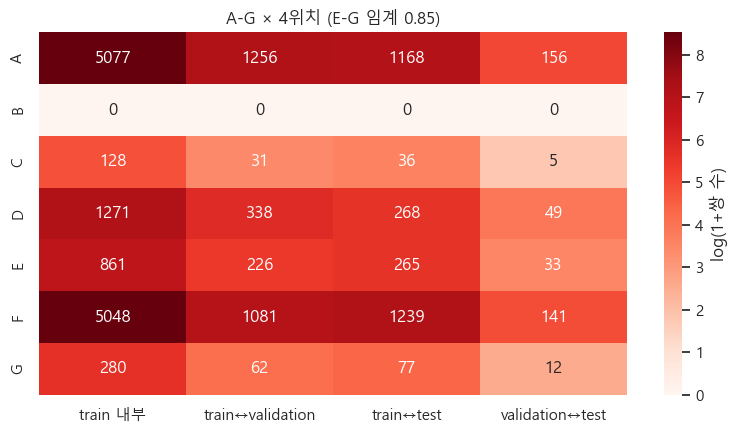

In [8]:
# 7유형 × 4위치 = 28칸 본표. validation/test 내부는 별도 참고표.
POS4 = ["train 내부", "train↔validation", "train↔test", "validation↔test"]
exact_long = exact_pairs.rename(columns={"case": "case_name"})[["row_a", "row_b", "case_name", "position"]]
fuzzy_long = fuzzy_pairs.rename(columns={"fuzzy_case": "case_name"})[["row_a", "row_b", "case_name", "position"]]
all_cases = pd.concat([exact_long, fuzzy_long], ignore_index=True)
table_28 = (pd.crosstab(all_cases.case_name, all_cases.position)
            .reindex(index=list("ABCDEFG"), columns=POS4, fill_value=0)
            .fillna(0).astype(int))
table_28["4위치 합"] = table_28.sum(axis=1)
table_28.to_csv(OUT_DIR / "table_28_A_to_G.csv", encoding="utf-8-sig")
display(table_28)

internal_reference = (pd.crosstab(all_cases.case_name, all_cases.position)
                      .reindex(index=list("ABCDEFG"), columns=["validation 내부", "test 내부"], fill_value=0)
                      .fillna(0).astype(int))
print("참고: validation/test 내부")
display(internal_reference)

fig, ax = plt.subplots(figsize=(8, 4.5))
matrix = table_28[POS4].to_numpy()
sns.heatmap(np.log1p(matrix), annot=matrix, fmt="d", cmap="Reds",
            xticklabels=POS4, yticklabels=list("ABCDEFG"), ax=ax, cbar_kws={"label": "log(1+쌍 수)"})
ax.set_title(f"A-G × 4위치 (E-G 임계 {FUZZY_THRESHOLD})")
plt.tight_layout(); plt.savefig(OUT_DIR / "02_AG_28cell_heatmap.png", dpi=160); plt.show()


## 4. 스플릿 전략과 오버피팅 방지

- **test 원본은 수정하지 않고 고정**한다. 중복 제거 버전은 test 점수를 고르기 위한 용도가 아니라 민감도 보고용이다.
- 문서 수준 위험(A, D, E, F)은 Union-Find 그룹으로 묶어 train/validation 양쪽에 갈라지지 않게 한다.
- C/G는 문서가 다르므로 자동으로 같은 사건이라 단정하지 않고, 정답 오염 의심 목록으로 보낸다.
- test와 연결된 문서 그룹은 학습 풀에서 제외한다. test **정답**은 사용하지 않는다.
- 하이퍼파라미터/디코딩/데이터 버전 선택은 공통 validation만 사용한다.
- train loss 하락 + validation loss 상승을 오버피팅 시작으로 보고 조기 종료한다.


In [9]:
class UnionFind:
    def __init__(self, ids): self.parent = {int(i): int(i) for i in ids}
    def find(self, x):
        x = int(x)
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.parent[max(ra, rb)] = min(ra, rb)

exact_doc_pairs = exact_pairs[exact_pairs.case.isin(["A", "B", "D"])][["row_a", "row_b"]]
fuzzy_doc_pairs = fuzzy_pairs[fuzzy_pairs.fuzzy_case.isin(["E", "F"])][["row_a", "row_b"]]
group_edges = pd.concat([exact_doc_pairs, fuzzy_doc_pairs], ignore_index=True).drop_duplicates()

union = UnionFind(full.row_id)
for row in group_edges.itertuples(index=False):
    union.union(row.row_a, row.row_b)
full["doc_group"] = [union.find(row_id) for row_id in full.row_id]

test_groups = set(full.loc[full.split.eq("test"), "doc_group"])
pool = full[full.split.ne("test")].copy()
pool["linked_to_test"] = pool.doc_group.isin(test_groups)

# C는 정답 오염 의심. 양쪽을 자동 폐기하지 않고 '보수 정제 버전'에서만 제외한다.
c_suspect_ids = set(exact_pairs.loc[exact_pairs.case.eq("C"), ["row_a", "row_b"]].to_numpy().ravel())
pool["c_suspect"] = pool.row_id.isin(c_suspect_ids)

# 가장 엄격한 풀: test 연결 문서, 고신뢰 노이즈, C 의심을 제외
strict_pool = (pool[~pool.linked_to_test & ~pool.high_confidence_noise & ~pool.c_suspect]
               .sort_values("row_id")
               .drop_duplicates(["key_document", "key_summary"], keep="first")
               .copy())

from sklearn.model_selection import GroupShuffleSplit
splitter = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=SEED)
train_idx, valid_idx = next(splitter.split(strict_pool, groups=strict_pool.doc_group))
clean_train = strict_pool.iloc[train_idx].copy()
clean_valid = strict_pool.iloc[valid_idx].copy()
assert not (set(clean_train.doc_group) & set(clean_valid.doc_group))
assert not (set(clean_train.doc_group) & test_groups)

# 같은 공통 validation으로 데이터 처리 효과를 비교하기 위한 학습 버전
valid_groups = set(clean_valid.doc_group)
raw_fixed_train = pool[~pool.doc_group.isin(valid_groups) & ~pool.linked_to_test].copy()
dedup_fixed_train = (raw_fixed_train.sort_values("row_id")
                     .drop_duplicates(["key_document", "key_summary"], keep="first"))
dedup_fixed_train = dedup_fixed_train[~dedup_fixed_train.c_suspect]
strict_fixed_train = clean_train.copy()

DATA_VERSIONS = {
    "RAW_FIXED": raw_fixed_train,
    "DEDUP_FIXED": dedup_fixed_train,
    "STRICT_GROUP": strict_fixed_train,
}
version_stats = pd.DataFrame([
    {"version": name, "train_rows": len(frame), "valid_rows": len(clean_valid),
     "train_groups": frame.doc_group.nunique(),
     "train_valid_shared_groups": len(set(frame.doc_group) & valid_groups),
     "test_linked_rows": int(frame.linked_to_test.sum()) if "linked_to_test" in frame else 0,
     "noise_rows": int(frame.high_confidence_noise.sum())}
    for name, frame in DATA_VERSIONS.items()
])
version_stats.to_csv(OUT_DIR / "split_version_stats.csv", index=False, encoding="utf-8-sig")
display(version_stats)

for name, frame in {**DATA_VERSIONS, "VALID_FIXED": clean_valid}.items():
    destination = VERSION_DIR / name
    destination.mkdir(exist_ok=True)
    frame[REQUIRED_COLUMNS + ["row_id", "doc_group"]].to_csv(
        destination / "data.csv", index=False, encoding="utf-8-sig")


,version,train_rows,valid_rows,train_groups,train_valid_shared_groups,test_linked_rows,noise_rows
0,RAW_FIXED,19762,2023,16673,0,0,831
1,DEDUP_FIXED,18604,2023,16658,0,0,561
2,STRICT_GROUP,18043,2023,16216,0,0,0


## [기존 학습 노트북 보완 2026-09-21] 요청 기준 v0·B2·v1·v2 정의

기존 `RAW_FIXED`, `DEDUP_FIXED`, `STRICT_GROUP` 결과는 이미 학습됐으므로 지우거나 이름만 바꾸지 않는다.
아래 셀은 요청한 실험 정의가 기존 버전과 어떻게 다른지 **감사(audit)** 하기 위해 추가했다.

- v0: 원본 train 그대로
- B2: train·validation에서 test와 본문이 완전히 같은 기사만 제외
- v1: B2 + train/validation 사이 동일 본문 제거 + train 내부 동일 본문 1건 유지
- v2: v1 + 반복·빈 요약·깨진 문자·본문보다 긴 요약 정답 제거
- test: 행·본문·정답을 수정하지 않고 별도 플래그만 생성

이 셀은 기존 모델을 다시 학습하지 않는다. 기존 점수를 새 이름으로 둔갑시키지 않고,
앞으로 재학습할 때 사용할 정확한 행 집합과 통계만 만든다.

In [10]:
# [추가] 요청 기준 데이터 버전 감사. 기존 DATA_VERSIONS와 학습 결과는 변경하지 않는다.
import hashlib as request_hashlib
import re as request_re
import unicodedata as request_unicodedata
from collections import Counter as RequestCounter
from pathlib import Path as RequestPath

import numpy as np
import pandas as pd
from IPython.display import display

REQUEST_REQUIRED_COLUMNS = [
    "date", "category", "press", "title", "document", "link", "summary"
]
request_root_candidates = [
    RequestPath.cwd(),
    RequestPath(r"C:\news_summary_balanced\최종본_BALANCED12H_VERIFIED_패키지"),
]
REQUEST_ROOT = next(
    (path for path in request_root_candidates if (path / "data" / "train.csv").exists()),
    None,
)
if REQUEST_ROOT is None:
    raise FileNotFoundError("기존 패키지의 data/train.csv 경로를 찾지 못했습니다.")
REQUEST_OUT_DIR = REQUEST_ROOT / "outputs"

def request_file_sha256(path):
    digest = request_hashlib.sha256()
    with RequestPath(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def request_normalize(value):
    text = request_unicodedata.normalize("NFKC", str(value))
    return request_re.sub(r"\s+", " ", text).strip()

def request_key(value):
    return request_hashlib.sha256(request_normalize(value).encode("utf-8")).hexdigest()

def request_repeat_4gram(value, minimum_count=3):
    words = str(value).split()
    if len(words) < 4:
        return False
    counts = RequestCounter(
        tuple(words[index:index+4]) for index in range(len(words) - 3)
    )
    return max(counts.values(), default=0) >= minimum_count

request_test_hash_before = request_file_sha256(REQUEST_ROOT / "data" / "test.csv")
request_splits = {}
request_offset = 0
for request_split_name in ("train", "validation", "test"):
    request_frame = pd.read_csv(REQUEST_ROOT / "data" / f"{request_split_name}.csv")
    assert list(request_frame.columns) == REQUEST_REQUIRED_COLUMNS
    request_frame["split"] = request_split_name
    request_frame["row_id"] = np.arange(
        request_offset, request_offset + len(request_frame), dtype=np.int64
    )
    request_offset += len(request_frame)
    request_frame["key_document"] = request_frame.document.map(request_key)
    request_frame["key_summary"] = request_frame.summary.map(request_key)
    request_frame["repeat_flag"] = request_frame.summary.map(request_repeat_4gram)
    request_splits[request_split_name] = request_frame

request_train = request_splits["train"].copy()
request_valid = request_splits["validation"].copy()
request_test = request_splits["test"].copy()

request_test_doc_keys = set(request_test.key_document)
request_valid_doc_keys = set(request_valid.key_document)

def definite_broken_target(frame):
    empty_summary = frame.summary.astype(str).str.strip().eq("")
    replacement_char = frame.summary.astype(str).str.contains("�", regex=False)
    summary_longer_than_document = (
        frame.summary.astype(str).str.len() > frame.document.astype(str).str.len()
    )
    return (
        frame.repeat_flag
        | empty_summary
        | replacement_char
        | summary_longer_than_document
    )

request_v0 = request_train.copy()
request_b2 = request_train[~request_train.key_document.isin(request_test_doc_keys)].copy()
request_v1 = (
    request_b2[~request_b2.key_document.isin(request_valid_doc_keys)]
    .sort_values("row_id")
    .drop_duplicates("key_document", keep="first")
    .copy()
)
request_v2 = request_v1[~definite_broken_target(request_v1)].copy()

request_common_valid = (
    request_valid[~request_valid.key_document.isin(request_test_doc_keys)]
    .sort_values("row_id")
    .drop_duplicates("key_document", keep="first")
    .copy()
)
request_common_valid = request_common_valid[
    ~definite_broken_target(request_common_valid)
].copy()

REQUEST_DATA_VERSIONS = {
    "v0_original": request_v0,
    "B2_test_overlap_removed": request_b2,
    "v1_exact_document_dedup": request_v1,
    "v2_v1_plus_broken_target_removed": request_v2,
}

request_stats = pd.DataFrame([
    {
        "version": name,
        "rows": len(frame),
        "unique_documents": frame.key_document.nunique(),
        "duplicate_document_rows": len(frame) - frame.key_document.nunique(),
        "definite_broken_target_rows": int(definite_broken_target(frame).sum()),
        "overlap_with_original_validation": int(
            frame.key_document.isin(request_valid_doc_keys).sum()
        ),
        "overlap_with_test": int(
            frame.key_document.isin(request_test_doc_keys).sum()
        ),
        "final_model_eligible": name.startswith("v1") or name.startswith("v2"),
    }
    for name, frame in REQUEST_DATA_VERSIONS.items()
])
request_stats = pd.concat([
    request_stats,
    pd.DataFrame([{
        "version": "common_validation",
        "rows": len(request_common_valid),
        "unique_documents": request_common_valid.key_document.nunique(),
        "duplicate_document_rows": 0,
        "definite_broken_target_rows": 0,
        "overlap_with_original_validation": 0,
        "overlap_with_test": 0,
        "final_model_eligible": False,
    }]),
], ignore_index=True)

request_test_flags = request_test[
    REQUEST_REQUIRED_COLUMNS + ["row_id"]
].copy()
request_test_flags["flag_doc_seen_in_train"] = request_test.key_document.isin(
    set(request_train.key_document)
)
request_test_flags["flag_doc_seen_in_validation"] = request_test.key_document.isin(
    set(request_valid.key_document)
)
request_test_flags["flag_summary_seen_in_train"] = request_test.key_summary.isin(
    set(request_train.key_summary)
)
request_test_flags["flag_definite_broken_target"] = definite_broken_target(request_test)

request_stats.to_csv(
    REQUEST_OUT_DIR / "requested_v0_B2_v1_v2_stats.csv",
    index=False,
    encoding="utf-8-sig",
)
request_test_flags.to_csv(
    REQUEST_OUT_DIR / "test_flags_only_requested_definition.csv",
    index=False,
    encoding="utf-8-sig",
)

assert len(request_v0) == len(request_splits["train"])
assert not (set(request_v1.key_document) & request_valid_doc_keys)
assert not (set(request_v1.key_document) & request_test_doc_keys)
assert set(request_v2.row_id).issubset(set(request_v1.row_id))
assert request_file_sha256(REQUEST_ROOT / "data" / "test.csv") == request_test_hash_before

print("기존 학습 결과는 변경하지 않았습니다.")
display(request_stats)
display(request_test_flags.filter(regex="^flag_").sum().to_frame("test rows"))

기존 학습 결과는 변경하지 않았습니다.


,version,rows,unique_documents,duplicate_document_rows,definite_broken_target_rows,overlap_with_original_validation,overlap_with_test,final_model_eligible
0,v0_original,22194,20287,1907,1984,855,882,False
1,B2_test_overlap_removed,21312,20013,1299,1580,460,0,False
2,v1_exact_document_dedup,19815,19815,0,1015,0,0,True
3,v2_v1_plus_broken_target_removed,18800,18800,0,0,0,0,True
4,common_validation,2168,2168,0,0,0,0,False


,test rows
flag_doc_seen_in_train,321
flag_doc_seen_in_validation,101
flag_summary_seen_in_train,322
flag_definite_broken_target,236


In [11]:
# 90:10 / 80:20 / 70:30 분할 통계. test는 건드리지 않는다.
# 점수 비교는 서로 다른 validation을 직접 비교하지 않고, 위 clean_valid 공통 평가셋을 사용한다.
ratio_rows = []
base_groups = strict_fixed_train.doc_group.drop_duplicates().to_numpy()
rng = np.random.default_rng(SEED)
shuffled_groups = rng.permutation(base_groups)
for label, ratio in {"S1": .90, "S2": .80, "S3": .70}.items():
    n_groups = max(1, int(len(shuffled_groups) * ratio / .90))
    selected = set(shuffled_groups[:min(n_groups, len(shuffled_groups))])
    train_part = strict_fixed_train[strict_fixed_train.doc_group.isin(selected)]
    ratio_rows.append({"split": label,
                       "nominal_train_validation": f"{round(ratio*100)}:{round((1-ratio)*100)}",
                       "train_rows_for_fixed_eval": len(train_part),
                       "fixed_validation_rows": len(clean_valid), "test_rows_fixed": len(splits["test"])})
ratio_table = pd.DataFrame(ratio_rows)
ratio_table.to_csv(OUT_DIR / "split_ratio_plan.csv", index=False, encoding="utf-8-sig")
display(ratio_table)
print("공정 비교용 validation은 모든 실험에서 동일하며, test는 마지막까지 평가하지 않습니다.")


,split,nominal_train_validation,train_rows_for_fixed_eval,fixed_validation_rows,test_rows_fixed
0,S1,90:10,18043,2023,2740
1,S2,80:20,16006,2023,2740
2,S3,70:30,13992,2023,2740


공정 비교용 validation은 모든 실험에서 동일하며, test는 마지막까지 평가하지 않습니다.


## 5. 토큰화와 임베딩

KoBART/KoGPT2의 BPE와 KoELECTRA의 WordPiece를 같은 문장으로 비교한다. 최종 토크나이저는
성능 취향이 아니라 **사전학습 가중치의 임베딩 행렬과 토큰 ID가 반드시 일치해야 한다**는 제약 때문에
KoBART 원래 토크나이저를 쓴다.


In [12]:
TOKENIZER_MODELS = {
    "KoBART (BPE)": "gogamza/kobart-base-v2",
    "KoGPT2 (BPE)": "skt/kogpt2-base-v2",
    "KoELECTRA (WordPiece)": "monologg/koelectra-base-v3-discriminator",
}
SAMPLE_TEXT = "정부가 수출 중소기업의 물류난 해소를 위해 무역금융 규모를 40조 원 이상 확대한다"
tokenizers_loaded, tokenizer_rows = {}, []
if RUN_TOKENIZER_DEMOS:
    try:
        from transformers import AutoTokenizer
        for label, model_name in TOKENIZER_MODELS.items():
            tokenizer_obj = AutoTokenizer.from_pretrained(model_name, local_files_only=True)
            pieces = tokenizer_obj.tokenize(SAMPLE_TEXT)
            tokenizers_loaded[label] = tokenizer_obj
            tokenizer_rows.append({"model": label, "method": label.split("(")[-1].rstrip(")"),
                                   "vocab_size": tokenizer_obj.vocab_size,
                                   "token_count": len(pieces), "tokens": " | ".join(pieces)})
        tokenizer_compare = pd.DataFrame(tokenizer_rows)
        tokenizer_compare.to_csv(OUT_DIR / "tokenizer_compare.csv", index=False, encoding="utf-8-sig")
        display(tokenizer_compare)
    except Exception as error:
        tokenizers_loaded = {}
        print("토크나이저 로드 생략:", type(error).__name__, str(error)[:200])
else:
    print("RUN_TOKENIZER_DEMOS=False - 오프라인 검증에서 토크나이저 로드를 건너뜁니다.")


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
c:\news_summary_balanced\최종본_BALANCED12H_VERIFIED_패키지\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


,model,method,vocab_size,token_count,tokens
0,KoBART (BPE),BPE,30000,17,▁정부가 | ▁수출 | ▁중소기업의 | ▁물류 | 난 | ▁해 | 소를 | ▁위해 ...
1,KoGPT2 (BPE),BPE,51200,19,▁정부가 | ▁수출 | ▁중소기업 | 의 | ▁물류 | 난 | ▁해 | 소를 | ▁...
2,KoELECTRA (WordPiece),WordPiece,35000,20,정부 | ##가 | 수출 | 중소기업 | ##의 | 물류 | ##난 | 해소 | #...


In [13]:
# KoBART 토큰 길이 분포와 512/1024 초과 비율
if "KoBART (BPE)" in tokenizers_loaded:
    kobart_tokenizer = tokenizers_loaded["KoBART (BPE)"]
    token_sample_n = min(3000, len(splits["train"]))
    token_sample = splits["train"].sample(token_sample_n, random_state=SEED)
    def token_lengths(texts, batch_size=128):
        lengths = []
        values = list(map(str, texts))
        for start in range(0, len(values), batch_size):
            encoded = kobart_tokenizer(values[start:start+batch_size], add_special_tokens=True,
                                       truncation=False, padding=False)
            lengths.extend(map(len, encoded["input_ids"]))
        return np.asarray(lengths)
    doc_token_lengths = token_lengths(token_sample.document)
    summary_token_lengths = token_lengths(token_sample.summary)
    token_length_stats = pd.DataFrame([{
        "sample_n": token_sample_n, "doc_median": int(np.median(doc_token_lengths)),
        "doc_p95": int(np.percentile(doc_token_lengths, 95)),
        "over_512_pct": float((doc_token_lengths > 512).mean() * 100),
        "over_1024_pct": float((doc_token_lengths > 1024).mean() * 100),
        "summary_median": int(np.median(summary_token_lengths)),
        "summary_p95": int(np.percentile(summary_token_lengths, 95)),
    }])
    display(token_length_stats.round(2))
    token_length_stats.to_csv(OUT_DIR / "token_length_stats.csv", index=False, encoding="utf-8-sig")
else:
    doc_token_lengths = summary_token_lengths = np.array([])
    print("KoBART 토크나이저가 없어 토큰 길이 계산을 건너뜁니다.")


,sample_n,doc_median,doc_p95,over_512_pct,over_1024_pct,summary_median,summary_p95
0,3000,352,943,27.33,3.9,72,122


In [14]:
# 고정 임베딩 Word2Vec - KoNLPy/JDK가 없으면 정규식 토큰화로 안전하게 폴백
try:
    from gensim.models import Word2Vec
    tokenize_for_w2v = lambda text: re.findall(r"[가-힣A-Za-z0-9]+", str(text))
    W2V_TOKENIZER = "정규식"
    if RUN_KONLPY_DEMO:
        try:
            from konlpy.tag import Okt
            _okt = Okt()
            tokenize_for_w2v = lambda text: _okt.morphs(str(text))
            W2V_TOKENIZER = "Okt 형태소"
        except Exception as error:
            warnings.warn(f"KoNLPy/JDK 초기화 실패 - 정규식 사용: {type(error).__name__}: {error}")
    w2v_source = splits["train"].sample(min(3000 if RUN_MODE == "SMOKE" else 5000,
                                             len(splits["train"])), random_state=SEED)
    w2v_sentences = [tokenize_for_w2v(text) for text in w2v_source.document]
    word2vec = Word2Vec(w2v_sentences, vector_size=128, window=5, min_count=5,
                       sg=1, epochs=3, seed=SEED, workers=1)
    print("Word2Vec tokenizer:", W2V_TOKENIZER, "| vocab:", len(word2vec.wv))
    for word in ("수출", "금리", "반도체"):
        if word in word2vec.wv:
            print(word, word2vec.wv.most_similar(word, topn=5))
except Exception as error:
    word2vec = None
    print("Word2Vec 데모 생략:", type(error).__name__, str(error)[:200])


Word2Vec tokenizer: 정규식 | vocab: 31936
수출 [('무역', 0.8732887506484985), ('수급', 0.8549233078956604), ('공급망', 0.8437387943267822), ('전망', 0.8394933938980103), ('애로', 0.8390306234359741)]
금리 [('인상', 0.9184300899505615), ('기준금리', 0.8755048513412476), ('이자', 0.8342611789703369), ('인상에', 0.8212267160415649), ('인상이', 0.8206058144569397)]
반도체 [('3나노', 0.8241774439811707), ('메모리', 0.8228617906570435), ('파운드리', 0.7972964644432068), ('차량용', 0.7906607389450073), ('부품', 0.7707930207252502)]


In [15]:
# 토큰 ID → 임베딩 → 인코더 → 디코더 shape와 문맥 임베딩 차이
if RUN_MODEL_EXPERIMENTS and "KoBART (BPE)" in tokenizers_loaded:
    from transformers import AutoModelForSeq2SeqLM
    probe_tokenizer = tokenizers_loaded["KoBART (BPE)"]
    probe_model = AutoModelForSeq2SeqLM.from_pretrained(
        "gogamza/kobart-base-v2", local_files_only=True).to(DEVICE).eval()
    encoded = probe_tokenizer(SAMPLE_TEXT, return_tensors="pt")
    encoded = {key: value.to(DEVICE) for key, value in encoded.items()
               if key in ("input_ids", "attention_mask")}
    with torch.inference_mode():
        embedding = probe_model.model.shared(encoded["input_ids"])
        encoder_output = probe_model.model.encoder(**encoded).last_hidden_state
        decoder_input = torch.tensor([[probe_model.config.decoder_start_token_id]], device=DEVICE)
        logits = probe_model(**encoded, decoder_input_ids=decoder_input).logits
    print("1 token IDs     ", tuple(encoded["input_ids"].shape))
    print("2 embeddings    ", tuple(embedding.shape))
    print("3 encoder output", tuple(encoder_output.shape))
    print("4 decoder logits", tuple(logits.shape))
    print("embedding→encoder mean abs change:",
          float((encoder_output - embedding).abs().mean().cpu()))

    # 같은 표면어 '수출'이 문맥에 따라 다른 벡터가 되는지 수치로 확인
    context_sentences = [
        "정부가 수출 중소기업의 무역금융을 확대한다",
        "그 배우는 새 드라마로 해외 시장 수출 판로를 넓혔다",
    ]
    context_vectors = []
    for sentence in context_sentences:
        item = probe_tokenizer(sentence, return_tensors="pt")
        item = {key: value.to(DEVICE) for key, value in item.items()
                if key in ("input_ids", "attention_mask")}
        pieces = probe_tokenizer.convert_ids_to_tokens(item["input_ids"][0])
        positions = [i for i, piece in enumerate(pieces) if "수출" in piece.replace("▁", "")]
        with torch.inference_mode():
            hidden = probe_model.model.encoder(**item).last_hidden_state[0]
        if not positions:
            raise ValueError(f"'수출' 토큰 위치를 찾지 못했습니다: {pieces}")
        context_vectors.append(hidden[positions].mean(0))
    contextual_cosine = float(torch.nn.functional.cosine_similarity(
        context_vectors[0][None], context_vectors[1][None]).cpu())
    print(f"같은 단어 '수출'의 두 문맥 KoBART cosine: {contextual_cosine:.4f}")
    print("Word2Vec의 같은 단어 벡터 cosine은 항상 1.0000입니다.")
    del probe_model, encoded, embedding, encoder_output, logits, context_vectors
    gc.collect(); torch.cuda.empty_cache()
else:
    print("호환 CUDA 환경에서 RUN_MODEL_EXPERIMENTS=True로 실행하면 단계별 shape가 출력됩니다.")


호환 CUDA 환경에서 RUN_MODEL_EXPERIMENTS=True로 실행하면 단계별 shape가 출력됩니다.


## 6. 모델 구조 선택

|구조|대표|요약 적합성|
|---|---|---|
|인코더 전용|ELECTRA/BERT|양방향 이해는 가능하지만 다음 토큰 생성 헤드가 없어 직접 요약 생성 불가|
|인코더-디코더|BART/T5|긴 입력과 짧은 출력이 분리되고 cross-attention으로 원문을 참조 - **주 모델**|
|디코더 전용|GPT|기사+요약을 한 시퀀스에 넣어야 하므로 긴 기사에서 입력 예산이 줄어듦 - 비교용|

KoBART는 손상 문장 복원 사전학습이 생성형 요약에 맞고, 한국어 사전학습 가중치를 그대로 전이할 수 있다.
KoGPT2 비교에서는 기사 토큰의 loss를 반드시 `-100`으로 마스킹해 **요약 부분만** 학습한다.


## 7. 평가 지표와 선택 이유

- **ROUGE-1 F1**: 핵심 단어 포함 정도. 정밀도와 재현율을 함께 반영한다.
- **ROUGE-2 F1**: 연속 2-gram 일치. 국소 표현/구문 일치를 더 엄격히 본다.
- **ROUGE-L F1**: 최장 공통 부분수열. 어순과 전체 흐름을 본다. validation의 주 선택 지표다.
- **BERTScore-F1**: 표면 단어가 달라도 문맥 의미가 가까우면 반영한다. ROUGE의 표현 다양성 약점을 보완한다.
- 반복률·숫자 불일치·길이: 높은 ROUGE만으로 숨을 수 있는 생성 품질 문제를 함께 본다.

`rouge_score` 기본 토크나이저는 한국어를 올바르게 처리하지 않으므로 공백 토크나이저를 명시한다.
형태소 ROUGE는 KoNLPy가 정상일 때 표본 민감도 분석으로만 비교하고, 모든 실험의 공식 수치는 공백 기준으로 고정한다.


In [16]:
from rouge_score import rouge_scorer

class SpaceTokenizer:
    def tokenize(self, text): return str(text).split()

ROUGE_SCORER = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"], tokenizer=SpaceTokenizer(), use_stemmer=False
)

def rouge_per_row(references, predictions):
    rows = []
    for reference, prediction in zip(references, predictions):
        scored = ROUGE_SCORER.score(str(reference), str(prediction))
        rows.append({metric: scored[metric].fmeasure for metric in ("rouge1", "rouge2", "rougeL")})
    return pd.DataFrame(rows)

def rouge_mean(references, predictions):
    scores = rouge_per_row(references, predictions)
    return {column: float(scores[column].mean()) for column in scores}

def repeat_rate(predictions):
    return float(np.mean([has_repeat(text) for text in predictions]))

def extract_numbers(text):
    # 55,900과 55900은 같은 것으로 본다. 한글 수사 표기는 사람 검토 대상이다.
    return set(re.findall(r"\d+(?:\.\d+)?%?", re.sub(r"(?<=\d),(?=\d)", "", str(text))))

def number_mismatch(document, prediction):
    return bool(extract_numbers(prediction) - extract_numbers(document))

# 실제 첨부 validation 전체에서 계산되는 비학습 기준선
valid_original = splits["validation"]
baseline_rows = []
for n_words in (50, 80):
    predictions = [" ".join(str(text).split()[:n_words]) for text in valid_original.document]
    baseline_rows.append({"baseline": f"Lead-{n_words} words",
                          **rouge_mean(valid_original.summary, predictions),
                          "mean_chars": float(np.mean(list(map(len, predictions))))})
lead_baselines = pd.DataFrame(baseline_rows)
lead_baselines.to_csv(OUT_DIR / "validation_lead_baselines.csv", index=False, encoding="utf-8-sig")
display(lead_baselines.round(4))


,baseline,rouge1,rouge2,rougeL,mean_chars
0,Lead-50 words,0.4580,0.3724,0.3890,207.7539
1,Lead-80 words,0.4623,0.3893,0.3944,320.7405


## 8. 전이학습 파이프라인 - 8GB GPU 안전 설정

원본 노트북처럼 3,000개를 `max_length=1024`로 미리 GPU에 올리지 않는다. CPU Dataset에서 문자열을 보관하고
배치마다 **동적 패딩**한다. 8GB에서는 물리 배치(`micro_batch`)를 1-2로 두고 gradient accumulation으로
유효 배치 4/8/16을 비교한다. 학습에는 AMP와 gradient checkpointing을 실제 적용한다.

예상 시간은 고정 숫자가 아니라 첫 실행의 `seconds/sample`을 전체 행 수에 곱해 계산한다.
RTX 5060 Laptop 8GB/최대 115W의 보수적 계획값은 다음과 같다.

- SMOKE 전체 점검: 약 **20-60분**(첫 모델 다운로드 제외)
- FAST10H 전체 탐색+전체 strict train+test 1회: 약 **6-9시간**
- BALANCED12H 주요 후보 비교+전체 strict train+test 1회: 약 **10-14시간**
- 전체 22,194건, 512토큰: 약 **1.4-2.0시간/epoch**
- 엄격 정제 18,041건, 512토큰: 약 **1.2-1.6시간/epoch**
- 전체 22,194건, 1024토큰: 약 **3-6시간/epoch**

사전 실측은 같은 RTX 5060 Laptop/CUDA 12.8에서 64건이 14.9-20.7초,
peak VRAM 2.33 GiB였다. 노트북의 실제 첫 epoch 추정표가 이 범위보다 우선한다.
전원 모드·TGP·열 스로틀링에 따라 2배 이상 차이날 수 있다.


In [17]:
if RUN_MODEL_EXPERIMENTS or RUN_REQUESTED_VERSION_RETRAINING or RUN_SELECTED_TEST_ONCE:
    from torch.utils.data import Dataset, DataLoader
    from transformers import AutoModelForSeq2SeqLM, AutoTokenizer, get_linear_schedule_with_warmup

    PRIMARY_MODEL = "gogamza/kobart-base-v2"
    main_tokenizer = AutoTokenizer.from_pretrained(PRIMARY_MODEL, local_files_only=True)

    class NewsDataset(Dataset):
        def __init__(self, frame):
            self.documents = frame.document.astype(str).tolist()
            self.summaries = frame.summary.astype(str).tolist()
        def __len__(self): return len(self.documents)
        def __getitem__(self, index): return self.documents[index], self.summaries[index]

    def make_collate(tokenizer, max_source, max_target):
        def collate(batch):
            documents, summaries = zip(*batch)
            inputs = tokenizer(list(documents), max_length=max_source, truncation=True,
                               padding=True, return_tensors="pt",
                               return_token_type_ids=False)
            labels = tokenizer(text_target=list(summaries), max_length=max_target,
                               truncation=True, padding=True, return_tensors="pt",
                               return_token_type_ids=False)["input_ids"]
            labels[labels == tokenizer.pad_token_id] = -100
            return {"input_ids": inputs["input_ids"],
                    "attention_mask": inputs["attention_mask"], "labels": labels}
        return collate

    def make_loader(frame, tokenizer, max_source, max_target, micro_batch, shuffle):
        generator = torch.Generator().manual_seed(SEED)
        return DataLoader(NewsDataset(frame), batch_size=micro_batch, shuffle=shuffle,
                          collate_fn=make_collate(tokenizer, max_source, max_target),
                          num_workers=0, pin_memory=True, generator=generator)

    def move_batch(batch):
        return {key: value.to(DEVICE, non_blocking=True) for key, value in batch.items()}

    def train_seq2seq(train_frame, valid_frame, *, learning_rate=3e-5, epochs=3,
                      max_source=512, max_target=160, micro_batch=2,
                      effective_batch=8, patience=2, save_dir=None):
        seed_everything()
        model = AutoModelForSeq2SeqLM.from_pretrained(
            PRIMARY_MODEL, local_files_only=True).to(DEVICE)
        model.gradient_checkpointing_enable()
        model.config.use_cache = False
        accumulation = max(1, math.ceil(effective_batch / micro_batch))
        train_loader = make_loader(train_frame, main_tokenizer, max_source, max_target,
                                   micro_batch, True)
        valid_loader = make_loader(valid_frame, main_tokenizer, max_source, max_target,
                                   micro_batch, False)
        optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=.01)
        update_steps = math.ceil(len(train_loader) / accumulation) * epochs
        scheduler = get_linear_schedule_with_warmup(
            optimizer, num_warmup_steps=max(1, int(update_steps * .06)),
            num_training_steps=max(1, update_steps))
        scaler = torch.amp.GradScaler("cuda", enabled=(USE_AMP and AMP_DTYPE == torch.float16))
        history, best_loss, best_state, stale = [], float("inf"), None, 0

        for epoch in range(1, epochs + 1):
            model.train(); optimizer.zero_grad(set_to_none=True)
            loss_sum, item_count = 0.0, 0
            if DEVICE == "cuda": torch.cuda.synchronize()
            started = time.perf_counter()
            for step, batch in enumerate(train_loader, 1):
                batch = move_batch(batch)
                with torch.amp.autocast("cuda", dtype=AMP_DTYPE,
                                        enabled=(DEVICE == "cuda" and USE_AMP)):
                    loss = model(**batch).loss
                    scaled_loss = loss / accumulation
                scaler.scale(scaled_loss).backward()
                if step % accumulation == 0 or step == len(train_loader):
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(optimizer); scaler.update(); scheduler.step()
                    optimizer.zero_grad(set_to_none=True)
                batch_items = batch["input_ids"].size(0)
                loss_sum += float(loss.detach()) * batch_items; item_count += batch_items
            if DEVICE == "cuda": torch.cuda.synchronize()
            train_seconds = time.perf_counter() - started

            model.eval(); valid_loss_sum, valid_items = 0.0, 0
            with torch.inference_mode():
                for batch in valid_loader:
                    batch = move_batch(batch)
                    with torch.amp.autocast("cuda", dtype=AMP_DTYPE,
                                            enabled=(DEVICE == "cuda" and USE_AMP)):
                        loss = model(**batch).loss
                    count = batch["input_ids"].size(0)
                    valid_loss_sum += float(loss) * count; valid_items += count
            train_loss = loss_sum / max(item_count, 1)
            valid_loss = valid_loss_sum / max(valid_items, 1)
            samples_per_second = item_count / max(train_seconds, 1e-9)
            history.append({"epoch": epoch, "train_loss": train_loss, "valid_loss": valid_loss,
                            "seconds": train_seconds, "samples_per_second": samples_per_second})
            print(f"epoch {epoch}: train {train_loss:.4f} | valid {valid_loss:.4f} | "
                  f"{train_seconds/60:.1f} min | {samples_per_second:.2f} samples/s")
            if valid_loss < best_loss - 1e-4:
                best_loss, stale = valid_loss, 0
                best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            else:
                stale += 1
                if stale >= patience:
                    print("early stopping: validation loss가 개선되지 않음")
                    break

        if best_state is not None:
            model.load_state_dict(best_state)
        model.config.use_cache = True
        model.gradient_checkpointing_disable()
        if save_dir is not None:
            save_dir = Path(save_dir); save_dir.mkdir(parents=True, exist_ok=True)
            model.save_pretrained(save_dir, safe_serialization=True)
            main_tokenizer.save_pretrained(save_dir)
        return model, pd.DataFrame(history)

    def generate_summaries(model, frame, generation, max_source=512, batch_size=4):
        model.eval(); predictions = []
        for start in range(0, len(frame), batch_size):
            batch = frame.iloc[start:start+batch_size]
            encoded = main_tokenizer(batch.document.astype(str).tolist(), padding=True,
                                     truncation=True, max_length=max_source,
                                     return_tensors="pt", return_token_type_ids=False)
            # 일부 KoBART 토크나이저 버전은 요청과 무관하게 token_type_ids를
            # 반환할 수 있다. KoBART generate에는 지원되지 않으므로 허용 키만 전달한다.
            encoded = {
                key: value.to(DEVICE) for key, value in encoded.items()
                if key in {"input_ids", "attention_mask"}
            }
            with torch.inference_mode(), torch.amp.autocast(
                "cuda", dtype=AMP_DTYPE, enabled=(DEVICE == "cuda" and USE_AMP)
            ):
                output_ids = model.generate(**encoded, max_new_tokens=CFG["max_target"],
                                            min_new_tokens=12, **generation)
            predictions.extend(main_tokenizer.batch_decode(output_ids, skip_special_tokens=True))
        return [text.strip() for text in predictions]

    def free_gpu_cache():
        gc.collect()
        torch.cuda.empty_cache()
else:
    PRIMARY_MODEL = "gogamza/kobart-base-v2"
    print("모델 학습 함수는 호환 CUDA 커널에서 활성화됩니다.")


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
c:\news_summary_balanced\최종본_BALANCED12H_VERIFIED_패키지\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


In [18]:
# 베이스라인 B(파인튜닝 전)와 실험 C(KoBART 파인튜닝)
# 모든 선택은 공통 clean_valid에서만 한다.
train_for_search = strict_fixed_train.sample(
    min(CFG["train_n"] or len(strict_fixed_train), len(strict_fixed_train)), random_state=SEED)
valid_for_search = clean_valid.sample(
    min(CFG["valid_n"] or len(clean_valid), len(clean_valid)), random_state=SEED)
valid_for_generation = valid_for_search.head(min(CFG["generation_n"], len(valid_for_search)))

TRANSFER_RESULTS = []
finetuned_model = None
finetune_history = pd.DataFrame()
if RUN_MODEL_EXPERIMENTS:
    pretrained_model = AutoModelForSeq2SeqLM.from_pretrained(
        PRIMARY_MODEL, local_files_only=True).to(DEVICE)
    before_predictions = generate_summaries(
        pretrained_model, valid_for_generation,
        {"num_beams": 4, "no_repeat_ngram_size": 3}, max_source=CFG["max_source"])
    before_scores = rouge_mean(valid_for_generation.summary, before_predictions)
    TRANSFER_RESULTS.append({"experiment": "pretrained_without_finetune", **before_scores})
    del pretrained_model
    free_gpu_cache()

    finetuned_model, finetune_history = train_seq2seq(
        train_for_search, valid_for_search, learning_rate=3e-5,
        epochs=CFG["epochs"], max_source=CFG["max_source"],
        max_target=CFG["max_target"], micro_batch=CFG["micro_batch"],
        effective_batch=CFG["effective_batch"])
    after_predictions = generate_summaries(
        finetuned_model, valid_for_generation,
        {"num_beams": 4, "no_repeat_ngram_size": 3}, max_source=CFG["max_source"])
    after_scores = rouge_mean(valid_for_generation.summary, after_predictions)
    TRANSFER_RESULTS.append({"experiment": "kobart_finetuned", **after_scores})
    log_experiment("kobart_finetuned", {"model": PRIMARY_MODEL, "n_train": len(train_for_search),
                   "epochs": CFG["epochs"], "max_source": CFG["max_source"],
                   "effective_batch": CFG["effective_batch"]},
                   {**after_scores, "best_valid_loss": float(finetune_history.valid_loss.min())},
                   "전이학습 효과")

    measured_speed = float(finetune_history.samples_per_second.iloc[-1])
    epoch_estimate = pd.DataFrame([
        {"target": "현재 strict train", "rows": len(strict_fixed_train),
         "minutes_per_epoch": len(strict_fixed_train) / measured_speed / 60},
        {"target": "원본 train", "rows": len(splits["train"]),
         "minutes_per_epoch": len(splits["train"]) / measured_speed / 60},
    ])
    epoch_estimate.to_csv(OUT_DIR / "epoch_time_estimate.csv", index=False, encoding="utf-8-sig")
    display(pd.DataFrame(TRANSFER_RESULTS).round(4))
    display(epoch_estimate.round(1))

    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    ax.plot(finetune_history.epoch, finetune_history.train_loss, "o-", label="train")
    ax.plot(finetune_history.epoch, finetune_history.valid_loss, "s--", label="validation")
    ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_title("오버피팅 확인")
    ax.legend(); plt.tight_layout(); plt.savefig(OUT_DIR / "03_loss_curve.png", dpi=150); plt.show()
    # 다음 sweep가 새 모델을 올릴 공간을 확보한다. 디코딩 때 다시 GPU로 이동한다.
    finetuned_model.to("cpu")
    free_gpu_cache()
else:
    print("학습 생략. 원본 validation의 Lead 기준선은 위 표에 이미 계산되어 있습니다.")


학습 생략. 원본 validation의 Lead 기준선은 위 표에 이미 계산되어 있습니다.


## 9. 하이퍼파라미터와 데이터 버전 실험

학습률 → 에폭 → 입력 길이 → 유효 배치 순서로 **한 번에 하나만** 바꾼다. 각 단계의 최적값만 다음 단계에 고정한다.
탐색은 작은 학습 표본, 같은 validation 표본, 같은 seed와 평가 함수로 실행한다. 데이터 처리 비교도 같은
`clean_valid`로 `RAW_FIXED → DEDUP_FIXED → STRICT_GROUP`만 바꾼다.


In [19]:
SEARCH_RESULTS = []
BEST_CONFIG = dict(learning_rate=3e-5, epochs=CFG["epochs"], max_source=CFG["max_source"],
                   max_target=CFG["max_target"], micro_batch=CFG["micro_batch"],
                   effective_batch=CFG["effective_batch"])

def run_validation_experiment(name, train_frame, config):
    model, history = train_seq2seq(train_frame, valid_for_search,
                                   learning_rate=config["learning_rate"],
                                   epochs=config["epochs"], max_source=config["max_source"],
                                   max_target=config["max_target"], micro_batch=config["micro_batch"],
                                   effective_batch=config["effective_batch"])
    predictions = generate_summaries(model, valid_for_generation,
                                     {"num_beams": 4, "no_repeat_ngram_size": 3},
                                     max_source=config["max_source"])
    scores = rouge_mean(valid_for_generation.summary, predictions)
    row = {"experiment": name, **config, **scores,
           "valid_loss": float(history.valid_loss.min()),
           "seconds_per_epoch": float(history.seconds.iloc[-1])}
    log_experiment(name, {**config, "n_train": len(train_frame)}, scores, "validation 선택용")
    del model
    free_gpu_cache()
    return row

if RUN_MODEL_EXPERIMENTS:
    # SMOKE는 흐름 확인, FAST10H는 최소 탐색, BALANCED12H는 주요 후보 비교, FULL은 장시간 비교다.
    stages = [
        ("learning_rate", CFG["lr_grid"]),
        ("epochs", CFG["epoch_grid"]),
        ("max_source", CFG["length_grid"]),
        ("effective_batch", CFG["batch_grid"]),
    ]
    for parameter, values in stages:
        stage_rows = []
        for value in values:
            trial = dict(BEST_CONFIG); trial[parameter] = value
            row = run_validation_experiment(f"hp_{parameter}_{value}", train_for_search, trial)
            SEARCH_RESULTS.append(row); stage_rows.append(row)
        stage_table = pd.DataFrame(stage_rows)
        selected_value = stage_table.loc[stage_table.rougeL.idxmax(), parameter]
        BEST_CONFIG[parameter] = (float(selected_value) if parameter == "learning_rate"
                                  else int(selected_value))
        print(parameter, "선택:", BEST_CONFIG[parameter])
        if parameter == "epochs" and "force_final_epochs" in CFG:
            print("시간 예산 적용: 최종 epochs =", CFG["force_final_epochs"])
            BEST_CONFIG["epochs"] = int(CFG["force_final_epochs"])
        if parameter == "max_source" and "force_final_max_source" in CFG:
            print("시간 예산 적용: 최종 max_source =", CFG["force_final_max_source"])
            BEST_CONFIG["max_source"] = int(CFG["force_final_max_source"])

    # 시간 제한 모드는 데이터/분할 비교를 모두 같은 1 epoch로 맞춰 공정성을 유지한다.
    comparison_config = dict(BEST_CONFIG)
    comparison_config["epochs"] = min(
        BEST_CONFIG["epochs"], CFG.get("comparison_epochs", BEST_CONFIG["epochs"]))

    # 데이터 버전 비교: 설정/validation 고정
    for version_name, version_frame in DATA_VERSIONS.items():
        sample_n = min(CFG["train_n"] or len(version_frame), len(version_frame))
        sampled = version_frame.sample(sample_n, random_state=SEED)
        SEARCH_RESULTS.append(run_validation_experiment(
            f"data_{version_name}", sampled, comparison_config))

    # 전이학습 데이터 양 10/50/100% 비교(같은 validation)
    for fraction in (.10, .50, 1.00):
        n_rows = max(2, int(len(train_for_search) * fraction))
        SEARCH_RESULTS.append(run_validation_experiment(
            f"data_size_{int(fraction*100)}pct",
            train_for_search.head(n_rows), comparison_config))

    # 90:10 / 80:20 / 70:30에 대응하는 학습 풀 크기 비교(공통 validation)
    group_order = list(shuffled_groups)
    for split_name, ratio in {"S1": .90, "S2": .80, "S3": .70}.items():
        n_groups = max(1, int(len(group_order) * ratio / .90))
        selected_groups = set(group_order[:min(n_groups, len(group_order))])
        ratio_train = strict_fixed_train[strict_fixed_train.doc_group.isin(selected_groups)]
        base_search_n = CFG["train_n"] or len(strict_fixed_train)
        proportional_n = max(2, int(base_search_n * len(ratio_train) / len(strict_fixed_train)))
        sample_n = min(proportional_n, len(ratio_train))
        ratio_train = ratio_train.sample(sample_n, random_state=SEED)
        SEARCH_RESULTS.append(run_validation_experiment(
            f"split_{split_name}_{round(ratio*100)}_{round((1-ratio)*100)}",
            ratio_train, comparison_config))

    search_table = pd.DataFrame(SEARCH_RESULTS)
    search_table.to_csv(OUT_DIR / "validation_experiments.csv", index=False, encoding="utf-8-sig")
    display(search_table.round(4))
    print("최종 설정(validation 기준):", BEST_CONFIG)
else:
    search_table = pd.DataFrame()
    print("하이퍼파라미터 학습 생략")


하이퍼파라미터 학습 생략


## 10. 디코딩 전략 - 재학습 없이 validation으로 선택

Greedy, beam 4/8, 3-gram 반복 억제, 길이 패널티, top-p sampling을 비교한다.
ROUGE-L뿐 아니라 평균 길이, 반복률, 원문에 없는 숫자 비율을 함께 보고 최종 전략을 정한다.
sampling은 표현 다양성은 늘지만 사실 오류 위험 때문에 요약 기본값으로는 권장하지 않는다.


In [20]:
DECODE_STRATEGIES = {
    "greedy": {"num_beams": 1},
    "beam4": {"num_beams": 4},
    "beam8": {"num_beams": 8},
    "beam4_norepeat": {"num_beams": 4, "no_repeat_ngram_size": 3},
    "beam4_len08": {"num_beams": 4, "no_repeat_ngram_size": 3, "length_penalty": .8},
    "beam4_len12": {"num_beams": 4, "no_repeat_ngram_size": 3, "length_penalty": 1.2},
    "top_p": {"do_sample": True, "top_p": .9, "temperature": .7},
}
decode_rows, decode_predictions = [], {}
BEST_DECODE_NAME = "beam4_norepeat"

if RUN_MODEL_EXPERIMENTS and finetuned_model is not None:
    finetuned_model.to(DEVICE)
    for name, generation in DECODE_STRATEGIES.items():
        seed_everything()
        predictions = generate_summaries(finetuned_model, valid_for_generation, generation,
                                         max_source=BEST_CONFIG["max_source"])
        decode_predictions[name] = predictions
        scores = rouge_mean(valid_for_generation.summary, predictions)
        decode_rows.append({"strategy": name, **scores,
                            "mean_chars": float(np.mean(list(map(len, predictions)))),
                            "repeat_rate": repeat_rate(predictions),
                            "number_mismatch_rate": float(np.mean([
                                number_mismatch(doc, pred)
                                for doc, pred in zip(valid_for_generation.document, predictions)]))})
    decode_table = pd.DataFrame(decode_rows)
    # 1순위 ROUGE-L, 동점권(0.002)은 반복/숫자 오류가 낮은 쪽
    best_rouge = decode_table.rougeL.max()
    finalists = decode_table[decode_table.rougeL >= best_rouge - .002]
    BEST_DECODE_NAME = finalists.sort_values(
        ["repeat_rate", "number_mismatch_rate", "rougeL"], ascending=[True, True, False]
    ).iloc[0].strategy
    decode_table.to_csv(OUT_DIR / "decoding_validation.csv", index=False, encoding="utf-8-sig")
    display(decode_table.round(4))
    print("선택:", BEST_DECODE_NAME, DECODE_STRATEGIES[BEST_DECODE_NAME])
    del finetuned_model
    finetuned_model = None
    free_gpu_cache()
else:
    decode_table = pd.DataFrame()
    print("디코딩 비교 생략 - 기본 안전값 beam4_norepeat 사용")


디코딩 비교 생략 - 기본 안전값 beam4_norepeat 사용


## 11. 구조 비교 - KoBART vs KoGPT2

`FAST10H`, `BALANCED12H`, `FULL`에서는 같은 학습 건수·에폭·유효 배치·validation·ROUGE 함수로 비교한다. KoGPT2 입력은
`[기사] + " 요약: " + [정답 요약]`이며, 기사/구분자 위치의 label을 `-100`으로 만들어 요약 loss만 계산한다.
전체 연결 후 오른쪽을 단순 truncate하면 정답이 사라지므로, 먼저 정답 토큰 예산을 확보하고 기사만 자른다.


In [21]:
STRUCTURE_RESULT = pd.DataFrame()
if RUN_MODEL_EXPERIMENTS and RUN_STRUCTURE_COMPARISON:
    from transformers import AutoConfig, AutoModel, AutoModelForCausalLM
    from torch.nn.utils.rnn import pad_sequence

    GPT_MODEL = "skt/kogpt2-base-v2"
    ELECTRA_MODEL = "monologg/koelectra-base-v3-discriminator"
    structure_facts = []
    for model_label, model_name in (("KoBART", PRIMARY_MODEL),
                                    ("KoGPT2", GPT_MODEL),
                                    ("KoELECTRA", ELECTRA_MODEL)):
        config = AutoConfig.from_pretrained(model_name, local_files_only=True)
        if getattr(config, "is_encoder_decoder", False):
            structure = "encoder-decoder"
        elif config.model_type in {"gpt2", "gpt_neo", "llama"}:
            structure = "decoder-only"
        else:
            structure = "encoder-only"
        structure_facts.append({"model": model_label, "model_type": config.model_type,
                                "structure": structure,
                                "is_encoder_decoder": bool(getattr(config, "is_encoder_decoder", False))})
    display(pd.DataFrame(structure_facts))

    # 생성 불가 구조 확인에는 학습 가중치가 필요 없다. 설정에서 모델 골격만
    # 만들면 수백 MB 다운로드와 네트워크 실패를 피하면서 can_generate를 확인할 수 있다.
    electra_config = AutoConfig.from_pretrained(ELECTRA_MODEL, local_files_only=True)
    electra_probe = AutoModel.from_config(electra_config)
    print("KoELECTRA can_generate():", electra_probe.can_generate(),
          "- 어휘 생성 LM head가 없어 요약 직접 생성 불가")
    del electra_probe
    free_gpu_cache()
    gpt_tokenizer = AutoTokenizer.from_pretrained(
        GPT_MODEL, bos_token="</s>", eos_token="</s>", pad_token="<pad>",
        local_files_only=True)
    separator_ids = gpt_tokenizer.encode(" 요약: ", add_special_tokens=False)

    class CausalSummaryDataset(Dataset):
        def __init__(self, frame, max_length=1024, max_target=160):
            self.frame = frame.reset_index(drop=True)
            self.max_length, self.max_target = max_length, max_target
        def __len__(self): return len(self.frame)
        def __getitem__(self, index):
            row = self.frame.iloc[index]
            target = gpt_tokenizer.encode(str(row.summary), add_special_tokens=False)[:self.max_target-1]
            target = target + [gpt_tokenizer.eos_token_id]
            source_budget = self.max_length - len(separator_ids) - len(target)
            source = gpt_tokenizer.encode(str(row.document), add_special_tokens=False)[:max(1, source_budget)]
            prompt = source + separator_ids
            ids = prompt + target
            labels = [-100] * len(prompt) + target
            return torch.tensor(ids), torch.tensor(labels)

    def causal_collate(batch):
        ids, labels = zip(*batch)
        input_ids = pad_sequence(ids, batch_first=True, padding_value=gpt_tokenizer.pad_token_id)
        label_ids = pad_sequence(labels, batch_first=True, padding_value=-100)
        return {"input_ids": input_ids, "attention_mask": input_ids.ne(gpt_tokenizer.pad_token_id),
                "labels": label_ids}

    def train_causal(train_frame, valid_frame, epochs, max_length, effective_batch):
        model = AutoModelForCausalLM.from_pretrained(
            GPT_MODEL, local_files_only=True).to(DEVICE)
        model.resize_token_embeddings(len(gpt_tokenizer)); model.gradient_checkpointing_enable()
        model.config.use_cache = False
        micro_batch = 1; accumulation = max(1, effective_batch // micro_batch)
        tr_loader = DataLoader(CausalSummaryDataset(train_frame, max_length, CFG["max_target"]),
                               batch_size=micro_batch, shuffle=True, collate_fn=causal_collate)
        va_loader = DataLoader(CausalSummaryDataset(valid_frame, max_length, CFG["max_target"]),
                               batch_size=micro_batch, shuffle=False, collate_fn=causal_collate)
        optimizer = torch.optim.AdamW(model.parameters(), lr=BEST_CONFIG["learning_rate"])
        scaler = torch.amp.GradScaler("cuda", enabled=(AMP_DTYPE == torch.float16))
        best_loss, best_state = float("inf"), None
        for epoch in range(epochs):
            model.train(); optimizer.zero_grad(set_to_none=True)
            for step, batch in enumerate(tr_loader, 1):
                batch = move_batch(batch)
                with torch.amp.autocast("cuda", dtype=AMP_DTYPE, enabled=True):
                    loss = model(**batch).loss / accumulation
                scaler.scale(loss).backward()
                if step % accumulation == 0 or step == len(tr_loader):
                    scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
            model.eval(); losses = []
            with torch.inference_mode():
                for batch in va_loader:
                    batch = move_batch(batch)
                    with torch.amp.autocast("cuda", dtype=AMP_DTYPE, enabled=True):
                        losses.append(float(model(**batch).loss))
            current = float(np.mean(losses))
            if current < best_loss:
                best_loss = current
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        model.load_state_dict(best_state); model.config.use_cache = True
        return model, best_loss

    def generate_gpt(model, frame, max_length=1024):
        old_side = gpt_tokenizer.padding_side; gpt_tokenizer.padding_side = "left"
        predictions = []
        for document in frame.document.astype(str):
            prompt_ids = gpt_tokenizer.encode(document, add_special_tokens=False)
            prompt_ids = prompt_ids[:max_length-CFG["max_target"]-len(separator_ids)] + separator_ids
            encoded = torch.tensor([prompt_ids], device=DEVICE)
            with torch.inference_mode():
                generated = model.generate(encoded, max_new_tokens=CFG["max_target"], num_beams=4,
                                           no_repeat_ngram_size=3,
                                           pad_token_id=gpt_tokenizer.pad_token_id,
                                           eos_token_id=gpt_tokenizer.eos_token_id)
            predictions.append(gpt_tokenizer.decode(generated[0, encoded.shape[1]:],
                                                    skip_special_tokens=True).strip())
        gpt_tokenizer.padding_side = old_side
        return predictions

    gpt_model, gpt_valid_loss = train_causal(
        train_for_search, valid_for_search, BEST_CONFIG["epochs"],
        min(1024, BEST_CONFIG["max_source"] + CFG["max_target"]),
        BEST_CONFIG["effective_batch"])
    gpt_predictions = generate_gpt(gpt_model, valid_for_generation)
    gpt_scores = rouge_mean(valid_for_generation.summary, gpt_predictions)
    bart_scores = next((row for row in TRANSFER_RESULTS if row["experiment"] == "kobart_finetuned"), None)
    STRUCTURE_RESULT = pd.DataFrame([
        {"model": "KoBART", "structure": "encoder-decoder", **(bart_scores or {})},
        {"model": "KoGPT2", "structure": "decoder-only", **gpt_scores,
         "valid_loss": gpt_valid_loss},
    ])
    STRUCTURE_RESULT.to_csv(OUT_DIR / "structure_comparison.csv", index=False, encoding="utf-8-sig")
    display(STRUCTURE_RESULT)
    del gpt_model
    free_gpu_cache()
else:
    print("구조 비교 학습 생략. FAST10H/BALANCED12H/FULL에서 같은 조건으로 비교합니다.")


구조 비교 학습 생략. FAST10H/BALANCED12H/FULL에서 같은 조건으로 비교합니다.


## 12. 최종 모델 확정과 test 1회

validation으로 확정한 설정을 저장한다. 학습 모드에서는 전체 strict train으로 선택된 epoch 수만큼 다시 학습한다.
test 셀은 `FINAL_TEST_DONE.json` 잠금 파일이 있으면 생성/평가를 반복하지 않고 기존 결과만 읽는다.

**절대 금지**: test 점수를 본 뒤 학습률, 데이터 정제, epoch, 디코딩을 바꾸는 것.


In [22]:
FINAL_CONFIG = {
    "model": PRIMARY_MODEL,
    "data_version": "STRICT_GROUP",
    **BEST_CONFIG,
    "decode_name": BEST_DECODE_NAME,
    "decode": DECODE_STRATEGIES[BEST_DECODE_NAME],
    "seed": SEED,
    "run_mode": RUN_MODE,
}
if RUN_PIPELINE_TO_FINAL_TEST:
    print("새 재학습 파이프라인 실행 중: 기존 final_config.json 덮어쓰기를 건너뜁니다.")
else:
    (OUT_DIR / "final_config.json").write_text(
        json.dumps(FINAL_CONFIG, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(FINAL_CONFIG, ensure_ascii=False, indent=2))

FINAL_MODEL_PATH = MODEL_DIR / "kobart_news_final"
if RUN_MODEL_EXPERIMENTS:
    if RUN_MODE in {"FAST10H", "BALANCED12H", "FULL"}:
        final_train_frame = strict_fixed_train
        final_valid_frame = clean_valid
    else:
        final_train_frame = train_for_search
        final_valid_frame = valid_for_search
    final_model, final_history = train_seq2seq(
        final_train_frame, final_valid_frame,
        learning_rate=BEST_CONFIG["learning_rate"], epochs=BEST_CONFIG["epochs"],
        max_source=BEST_CONFIG["max_source"], max_target=BEST_CONFIG["max_target"],
        micro_batch=BEST_CONFIG["micro_batch"],
        effective_batch=BEST_CONFIG["effective_batch"],
        patience=BEST_CONFIG["epochs"] + 1, save_dir=FINAL_MODEL_PATH)
    del final_model
    free_gpu_cache()
    print("최종 모델 저장:", FINAL_MODEL_PATH)
else:
    print("최종 학습 생략")


새 재학습 파이프라인 실행 중: 기존 final_config.json 덮어쓰기를 건너뜁니다.
최종 학습 생략


In [23]:
FINAL_TEST_LOCK = OUT_DIR / "FINAL_TEST_DONE.json"
FINAL_PREDICTIONS_PATH = OUT_DIR / "final_test_predictions.csv"
final_results = None

if RUN_FINAL_TEST:
    if RUN_MODE not in {"FAST10H", "BALANCED12H", "FULL"}:
        raise RuntimeError("최종 test는 FAST10H, BALANCED12H 또는 FULL에서만 허용합니다.")
    if not FINAL_MODEL_PATH.exists():
        raise FileNotFoundError("최종 모델이 없습니다. 먼저 학습 모드 실행을 완료하세요.")
    if FINAL_TEST_LOCK.exists() and FINAL_PREDICTIONS_PATH.exists():
        print("test 잠금 감지 - 재생성하지 않고 기존 결과를 읽습니다.")
        final_result_df = pd.read_csv(FINAL_PREDICTIONS_PATH)
        final_results = json.loads(FINAL_TEST_LOCK.read_text(encoding="utf-8"))
    else:
        final_tokenizer = AutoTokenizer.from_pretrained(
            FINAL_MODEL_PATH, local_files_only=True)
        main_tokenizer = final_tokenizer
        final_model = AutoModelForSeq2SeqLM.from_pretrained(
            FINAL_MODEL_PATH, local_files_only=True).to(DEVICE)
        official_test = splits["test"].copy()
        started = time.perf_counter()
        test_predictions = generate_summaries(
            final_model, official_test, FINAL_CONFIG["decode"],
            max_source=FINAL_CONFIG["max_source"], batch_size=2)
        generation_seconds = time.perf_counter() - started
        per_row = rouge_per_row(official_test.summary, test_predictions)
        final_result_df = official_test.copy()
        final_result_df["prediction"] = test_predictions
        for column in per_row:
            final_result_df[column] = per_row[column].to_numpy()
        final_result_df["repeat_flag"] = final_result_df.prediction.map(has_repeat)
        final_result_df["number_mismatch"] = [
            number_mismatch(doc, pred)
            for doc, pred in zip(final_result_df.document, final_result_df.prediction)]

        if RUN_BERTSCORE:
            try:
                from bert_score import score as bert_score
                _, _, bert_f1 = bert_score(
                    final_result_df.prediction.astype(str).tolist(),
                    final_result_df.summary.astype(str).tolist(),
                    model_type="bert-base-multilingual-cased", num_layers=9,
                    batch_size=8, device=DEVICE, verbose=True)
                final_result_df["bertscore_f1"] = bert_f1.cpu().numpy()
            except Exception as error:
                warnings.warn(f"BERTScore 생략: {type(error).__name__}: {error}")

        final_result_df.to_csv(FINAL_PREDICTIONS_PATH, index=False, encoding="utf-8-sig")
        final_results = {
            **{metric: float(final_result_df[metric].mean())
               for metric in ("rouge1", "rouge2", "rougeL")},
            "bertscore_f1": (float(final_result_df.bertscore_f1.mean())
                             if "bertscore_f1" in final_result_df else None),
            "repeat_rate": float(final_result_df.repeat_flag.mean()),
            "number_mismatch_rate": float(final_result_df.number_mismatch.mean()),
            "mean_prediction_chars": float(final_result_df.prediction.str.len().mean()),
            "n_test": len(final_result_df),
            "generation_seconds": generation_seconds,
            "completed_at": datetime.datetime.now().isoformat(timespec="seconds"),
        }
        FINAL_TEST_LOCK.write_text(json.dumps(final_results, ensure_ascii=False, indent=2), encoding="utf-8")
        log_experiment("FINAL_TEST_ONCE", FINAL_CONFIG, final_results, "test 1회 평가")
        del final_model
        free_gpu_cache()
    display(pd.Series(final_results, name="final_test"))
else:
    print("RUN_FINAL_TEST=False - 정상입니다. validation 선택 후 학습 모드에서 한 번만 True로 바꾸세요.")


RUN_FINAL_TEST=False - 정상입니다. validation 선택 후 학습 모드에서 한 번만 True로 바꾸세요.


## [재학습 추가 2026-09-21] 요청 데이터 버전의 공정한 재학습

이 절은 **새 노트북이 아니라 현재 노트북 안에서** v0·B2·v1·v2를 같은 조건으로 다시 학습한다.

- `v0_original`: 원본 train 그대로인 비교 기준선
- `B2_test_overlap_removed`: train에서 test 본문 완전중복만 제거
- `v1_exact_document_dedup`: B2에서 validation 중복과 train 내부 본문 완전중복까지 제거
- `v2_v1_plus_broken_target_removed`: v1에서 명백한 반복·빈 요약·깨진 문자 정답 제거
- test는 어떤 경우에도 삭제·수정하지 않고 마지막에 선택된 모델을 한 번만 평가

대화에서 말한 “summary 없이 본문만” 기준선은 정답 없이 지도학습할 수 없으므로, **뉴스 요약 정답으로 미세조정하지 않은 사전학습 KoBART**로 명확히 구현한다. Lead-50·Lead-80도 같은 validation에서 함께 계산한다.

모델 비교용 validation은 네 학습셋 중 어느 쪽과도 본문이 겹치지 않고 test와도 겹치지 않는 2,032건으로 고정한다. 따라서 v0의 중복 문제를 의도적으로 보여 주면서도 validation 점수가 학습 본문 암기로 부풀어 오르는 것을 막는다.

실행 순서:

1. 맨 위 실행 설정에서 `RUN_REQUESTED_VERSION_RETRAINING=True`로 변경한다.
2. `RUN_MODEL_EXPERIMENTS=False`는 그대로 둔다. 기존 탐색을 반복하지 않고 재학습 절차만 실행된다.
3. validation 비교표와 `selected_version.json`을 확인한다.
4. 최종 test가 필요할 때만 `RUN_SELECTED_TEST_ONCE=True`, 확인 문자열을 정확히 입력한다.

이미 완료된 버전은 완료표시와 설정이 일치하면 이어받아 재학습하지 않는다. 버전별 모델·학습곡선·validation 예측은 서로 다른 폴더에 저장한다.


In [24]:
# [재학습 추가] 실행 스위치와 공통 validation 고정
# 안전 기본값: 노트북을 다시 열거나 Run All 했을 때 수십 시간 학습/test가 자동 시작되지 않는다.
RUN_REQUESTED_VERSION_RETRAINING = globals().get(
    "RUN_REQUESTED_VERSION_RETRAINING", False
)
RUN_SELECTED_TEST_ONCE = globals().get("RUN_SELECTED_TEST_ONCE", False)
SELECTED_TEST_CONFIRM = globals().get("SELECTED_TEST_CONFIRM", "")
RETRAIN_RESUME_EXISTING = globals().get("RETRAIN_RESUME_EXISTING", True)
RUN_REQUESTED_BERTSCORE = globals().get("RUN_REQUESTED_BERTSCORE", False)

# 기존 최종 test가 실제로 사용한 조건을 고정했다(experiment_log.jsonl 기준).
# 네 데이터 버전 비교에서 바뀌는 것은 학습 데이터뿐이다.
REQUESTED_RETRAIN_CONFIG = {
    "model": "gogamza/kobart-base-v2",
    "learning_rate": 5e-5,
    "epochs": 2,
    "max_source": 512,
    "max_target": 160,
    "micro_batch": 2,
    "effective_batch": 4,
    "decode_name": "beam4_len08",
    "decode": {
        "num_beams": 4,
        "no_repeat_ngram_size": 3,
        "length_penalty": 0.8,
    },
    "seed": SEED,
}

REQUESTED_RETRAIN_VERSION_NAMES = [
    "v0_original",
    "B2_test_overlap_removed",
    "v1_exact_document_dedup",
    "v2_v1_plus_broken_target_removed",
]
REQUESTED_FINAL_ELIGIBLE = [
    "v1_exact_document_dedup",
    "v2_v1_plus_broken_target_removed",
]

REQUEST_RETRAIN_DIR = OUT_DIR / "requested_retraining"
REQUEST_MODEL_DIR = MODEL_DIR / "requested_retraining"
REQUEST_RETRAIN_DIR.mkdir(parents=True, exist_ok=True)
REQUEST_MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 공정한 공통 validation:
# 1) 원본 train과 본문이 겹치지 않음, 2) test와 겹치지 않음,
# 3) validation 내부 본문 중복 제거, 4) 명백히 망가진 정답 제거.
request_original_train_keys = set(request_train.key_document)
request_test_keys = set(request_test.key_document)
REQUEST_SAFE_VALIDATION = (
    request_valid[
        ~request_valid.key_document.isin(request_original_train_keys | request_test_keys)
    ]
    .sort_values("row_id")
    .drop_duplicates("key_document", keep="first")
    .copy()
)
REQUEST_SAFE_VALIDATION = REQUEST_SAFE_VALIDATION[
    ~definite_broken_target(REQUEST_SAFE_VALIDATION)
].copy()

assert len(REQUEST_SAFE_VALIDATION) == 2032, (
    "공통 validation 행 수가 예상과 다릅니다. 원본 CSV가 바뀌었는지 확인하세요: "
    f"{len(REQUEST_SAFE_VALIDATION):,}"
)
assert not set(REQUEST_SAFE_VALIDATION.key_document) & request_original_train_keys
assert not set(REQUEST_SAFE_VALIDATION.key_document) & request_test_keys
assert REQUEST_SAFE_VALIDATION.key_document.is_unique

for requested_name in REQUESTED_RETRAIN_VERSION_NAMES:
    if requested_name not in REQUEST_DATA_VERSIONS:
        raise KeyError(f"REQUEST_DATA_VERSIONS에 {requested_name}이 없습니다.")

requested_protocol = {
    "purpose": "v0/B2/v1/v2 same-condition retraining",
    "selection_split": "leakage-safe fixed validation",
    "selection_validation_rows": len(REQUEST_SAFE_VALIDATION),
    "test_policy": "untouched, selected model only, one locked evaluation",
    "versions": {
        name: len(REQUEST_DATA_VERSIONS[name])
        for name in REQUESTED_RETRAIN_VERSION_NAMES
    },
    "final_eligible": REQUESTED_FINAL_ELIGIBLE,
    "config": REQUESTED_RETRAIN_CONFIG,
}
(REQUEST_RETRAIN_DIR / "retraining_protocol.json").write_text(
    json.dumps(requested_protocol, ensure_ascii=False, indent=2), encoding="utf-8"
)
REQUEST_SAFE_VALIDATION.to_csv(
    REQUEST_RETRAIN_DIR / "fixed_safe_validation.csv",
    index=False,
    encoding="utf-8-sig",
)
display(pd.DataFrame([
    {
        "version": name,
        "train_rows": len(REQUEST_DATA_VERSIONS[name]),
        "fixed_validation_rows": len(REQUEST_SAFE_VALIDATION),
        "final_candidate": name in REQUESTED_FINAL_ELIGIBLE,
    }
    for name in REQUESTED_RETRAIN_VERSION_NAMES
]))
print("재학습 설정 저장:", REQUEST_RETRAIN_DIR / "retraining_protocol.json")


,version,train_rows,fixed_validation_rows,final_candidate
0,v0_original,22194,2032,False
1,B2_test_overlap_removed,21312,2032,False
2,v1_exact_document_dedup,19815,2032,True
3,v2_v1_plus_broken_target_removed,18800,2032,True


재학습 설정 저장: c:\news_summary_balanced\최종본_BALANCED12H_VERIFIED_패키지\outputs\requested_retraining\retraining_protocol.json


In [25]:
# [재학습 추가] v0·B2·v1·v2 동일 조건 재학습 및 validation 비교
REQUESTED_VERSION_RESULTS = pd.DataFrame()

def requested_model_complete(model_dir, expected_config):
    marker = Path(model_dir) / "training_complete.json"
    weights_exist = any(Path(model_dir).glob("model*.safetensors"))
    if not marker.exists() or not weights_exist:
        return False
    saved = json.loads(marker.read_text(encoding="utf-8"))
    return saved.get("config") == expected_config

def requested_validation_metrics(frame, predictions):
    per_row = rouge_per_row(frame.summary, predictions)
    return {
        "rouge1": float(per_row.rouge1.mean()),
        "rouge2": float(per_row.rouge2.mean()),
        "rougeL": float(per_row.rougeL.mean()),
        "repeat_rate": repeat_rate(predictions),
        "number_mismatch_rate": float(np.mean([
            number_mismatch(document, prediction)
            for document, prediction in zip(frame.document, predictions)
        ])),
        "mean_prediction_chars": float(np.mean(list(map(len, predictions)))),
    }, per_row

if RUN_REQUESTED_VERSION_RETRAINING:
    if not (RUN_MODEL_EXPERIMENTS or RUN_REQUESTED_VERSION_RETRAINING):
        raise RuntimeError(
            "맨 위 실행 설정에서 RUN_REQUESTED_VERSION_RETRAINING=True로 바꾼 뒤 "
            "처음부터 이 셀까지 실행하세요."
        )
    if DEVICE != "cuda":
        raise RuntimeError("전체 재학습은 CUDA GPU 환경에서만 실행하도록 제한했습니다.")

    requested_result_rows = []

    # 기준선 1: 요약 정답으로 미세조정하지 않은 사전학습 KoBART.
    # 'summary 없이 지도학습'은 목적함수를 만들 수 없으므로 이 정의가 재현 가능한 해석이다.
    main_tokenizer = AutoTokenizer.from_pretrained(
        REQUESTED_RETRAIN_CONFIG["model"], local_files_only=True
    )
    pretrained_baseline = AutoModelForSeq2SeqLM.from_pretrained(
        REQUESTED_RETRAIN_CONFIG["model"], local_files_only=True
    ).to(DEVICE)
    pretrained_predictions = generate_summaries(
        pretrained_baseline,
        REQUEST_SAFE_VALIDATION,
        REQUESTED_RETRAIN_CONFIG["decode"],
        max_source=REQUESTED_RETRAIN_CONFIG["max_source"],
        batch_size=2,
    )
    pretrained_metrics, pretrained_per_row = requested_validation_metrics(
        REQUEST_SAFE_VALIDATION, pretrained_predictions
    )
    pretrained_prediction_frame = REQUEST_SAFE_VALIDATION[
        REQUEST_REQUIRED_COLUMNS + ["row_id", "key_document"]
    ].copy()
    pretrained_prediction_frame["prediction"] = pretrained_predictions
    for metric_name in ("rouge1", "rouge2", "rougeL"):
        pretrained_prediction_frame[metric_name] = pretrained_per_row[metric_name].to_numpy()
    pretrained_dir = REQUEST_RETRAIN_DIR / "pretrained_no_summary_finetune"
    pretrained_dir.mkdir(parents=True, exist_ok=True)
    pretrained_prediction_frame.to_csv(
        pretrained_dir / "validation_predictions.csv",
        index=False,
        encoding="utf-8-sig",
    )
    requested_result_rows.append({
        "system": "KoBART_pretrained_no_summary_finetune",
        "kind": "no_task_finetuning_baseline",
        "n_train": 0,
        "n_validation": len(REQUEST_SAFE_VALIDATION),
        "best_valid_loss": np.nan,
        **pretrained_metrics,
    })
    del pretrained_baseline
    free_gpu_cache()

    for requested_name in REQUESTED_RETRAIN_VERSION_NAMES:
        print("\n" + "=" * 72)
        print("재학습 버전:", requested_name)
        train_frame = REQUEST_DATA_VERSIONS[requested_name].copy()
        version_model_dir = REQUEST_MODEL_DIR / requested_name
        version_output_dir = REQUEST_RETRAIN_DIR / requested_name
        version_output_dir.mkdir(parents=True, exist_ok=True)

        expected_complete = {
            "version": requested_name,
            "n_train": len(train_frame),
            "n_validation": len(REQUEST_SAFE_VALIDATION),
            "config": REQUESTED_RETRAIN_CONFIG,
        }
        reuse = RETRAIN_RESUME_EXISTING and requested_model_complete(
            version_model_dir, REQUESTED_RETRAIN_CONFIG
        )

        main_tokenizer = AutoTokenizer.from_pretrained(
            REQUESTED_RETRAIN_CONFIG["model"], local_files_only=True
        )
        if reuse:
            print("완료된 동일 설정 모델 재사용:", version_model_dir)
            requested_model = AutoModelForSeq2SeqLM.from_pretrained(
                version_model_dir, local_files_only=True
            ).to(DEVICE)
            history_path = version_output_dir / "training_history.csv"
            requested_history = (
                pd.read_csv(history_path) if history_path.exists() else pd.DataFrame()
            )
        else:
            requested_model, requested_history = train_seq2seq(
                train_frame,
                REQUEST_SAFE_VALIDATION,
                learning_rate=REQUESTED_RETRAIN_CONFIG["learning_rate"],
                epochs=REQUESTED_RETRAIN_CONFIG["epochs"],
                max_source=REQUESTED_RETRAIN_CONFIG["max_source"],
                max_target=REQUESTED_RETRAIN_CONFIG["max_target"],
                micro_batch=REQUESTED_RETRAIN_CONFIG["micro_batch"],
                effective_batch=REQUESTED_RETRAIN_CONFIG["effective_batch"],
                patience=REQUESTED_RETRAIN_CONFIG["epochs"] + 1,
                save_dir=version_model_dir,
            )
            requested_history.to_csv(
                version_output_dir / "training_history.csv",
                index=False,
                encoding="utf-8-sig",
            )
            (version_model_dir / "training_complete.json").write_text(
                json.dumps(expected_complete, ensure_ascii=False, indent=2),
                encoding="utf-8",
            )

        main_tokenizer = AutoTokenizer.from_pretrained(
            version_model_dir, local_files_only=True
        )
        requested_predictions = generate_summaries(
            requested_model,
            REQUEST_SAFE_VALIDATION,
            REQUESTED_RETRAIN_CONFIG["decode"],
            max_source=REQUESTED_RETRAIN_CONFIG["max_source"],
            batch_size=2,
        )
        requested_metrics, requested_per_row = requested_validation_metrics(
            REQUEST_SAFE_VALIDATION, requested_predictions
        )
        requested_prediction_frame = REQUEST_SAFE_VALIDATION[
            REQUEST_REQUIRED_COLUMNS + ["row_id", "key_document"]
        ].copy()
        requested_prediction_frame["prediction"] = requested_predictions
        for metric_name in ("rouge1", "rouge2", "rougeL"):
            requested_prediction_frame[metric_name] = requested_per_row[metric_name].to_numpy()
        requested_prediction_frame.to_csv(
            version_output_dir / "validation_predictions.csv",
            index=False,
            encoding="utf-8-sig",
        )

        result_row = {
            "system": requested_name,
            "kind": "trained_model",
            "n_train": len(train_frame),
            "n_validation": len(REQUEST_SAFE_VALIDATION),
            "best_valid_loss": (
                float(requested_history.valid_loss.min())
                if not requested_history.empty else np.nan
            ),
            **requested_metrics,
        }
        requested_result_rows.append(result_row)
        log_experiment(
            f"requested_retrain_{requested_name}",
            {
                **REQUESTED_RETRAIN_CONFIG,
                "n_train": len(train_frame),
                "n_validation": len(REQUEST_SAFE_VALIDATION),
            },
            requested_metrics,
            "고정 누수방지 validation에서 데이터 버전 비교",
        )
        del requested_model
        free_gpu_cache()

    # 학습하지 않는 Lead 기준선도 같은 validation에서 계산한다.
    for lead_words in (50, 80):
        lead_predictions = [
            " ".join(str(document).split()[:lead_words])
            for document in REQUEST_SAFE_VALIDATION.document
        ]
        lead_metrics, _ = requested_validation_metrics(
            REQUEST_SAFE_VALIDATION, lead_predictions
        )
        requested_result_rows.append({
            "system": f"Lead-{lead_words}",
            "kind": "extractive_baseline",
            "n_train": 0,
            "n_validation": len(REQUEST_SAFE_VALIDATION),
            "best_valid_loss": np.nan,
            **lead_metrics,
        })

    REQUESTED_VERSION_RESULTS = pd.DataFrame(requested_result_rows)
    REQUESTED_VERSION_RESULTS.to_csv(
        REQUEST_RETRAIN_DIR / "validation_model_comparison.csv",
        index=False,
        encoding="utf-8-sig",
    )

    # 최종 후보는 사전에 정한 v1/v2뿐이다. test 점수는 선택에 사용하지 않는다.
    eligible = REQUESTED_VERSION_RESULTS[
        REQUESTED_VERSION_RESULTS.system.isin(REQUESTED_FINAL_ELIGIBLE)
    ].copy()
    selected_row = eligible.sort_values(
        ["rougeL", "repeat_rate", "number_mismatch_rate"],
        ascending=[False, True, True],
    ).iloc[0]
    selected_payload = {
        "selected_version": selected_row.system,
        "selection_rule": "highest fixed-validation ROUGE-L; tie-break lower repetition then number mismatch",
        "test_used_for_selection": False,
        "validation_metrics": selected_row.to_dict(),
        "model_dir": str(REQUEST_MODEL_DIR / selected_row.system),
        "config": REQUESTED_RETRAIN_CONFIG,
    }
    (REQUEST_RETRAIN_DIR / "selected_version.json").write_text(
        json.dumps(selected_payload, ensure_ascii=False, indent=2, default=str),
        encoding="utf-8",
    )

    # v1과 v2의 차이가 우연 범위인지 paired bootstrap으로 함께 제시한다.
    v1_predictions = pd.read_csv(
        REQUEST_RETRAIN_DIR / "v1_exact_document_dedup" / "validation_predictions.csv"
    ).sort_values("row_id")
    v2_predictions = pd.read_csv(
        REQUEST_RETRAIN_DIR / "v2_v1_plus_broken_target_removed" / "validation_predictions.csv"
    ).sort_values("row_id")
    assert v1_predictions.row_id.tolist() == v2_predictions.row_id.tolist()
    requested_bootstrap_rows = []
    requested_rng = np.random.default_rng(SEED)
    for metric_name in ("rouge1", "rouge2", "rougeL"):
        delta = (
            v2_predictions[metric_name].to_numpy(float)
            - v1_predictions[metric_name].to_numpy(float)
        )
        bootstrap_means = np.empty(5000, dtype=float)
        for start in range(0, 5000, 250):
            stop = min(start + 250, 5000)
            indexes = requested_rng.integers(
                0, len(delta), size=(stop - start, len(delta))
            )
            bootstrap_means[start:stop] = delta[indexes].mean(axis=1)
        low, high = np.quantile(bootstrap_means, [0.025, 0.975])
        requested_bootstrap_rows.append({
            "metric": metric_name,
            "comparison": "v2_minus_v1",
            "mean_delta": float(delta.mean()),
            "ci95_low": float(low),
            "ci95_high": float(high),
            "two_sided_p": float(
                min(1.0, 2 * min(
                    np.mean(bootstrap_means <= 0),
                    np.mean(bootstrap_means >= 0),
                ))
            ),
        })
    requested_bootstrap = pd.DataFrame(requested_bootstrap_rows)
    requested_bootstrap.to_csv(
        REQUEST_RETRAIN_DIR / "v1_v2_paired_bootstrap.csv",
        index=False,
        encoding="utf-8-sig",
    )
    display(REQUESTED_VERSION_RESULTS.sort_values("rougeL", ascending=False).round(4))
    display(requested_bootstrap.round(4))
    print("최종 test 후보:", selected_payload["selected_version"])
else:
    comparison_path = REQUEST_RETRAIN_DIR / "validation_model_comparison.csv"
    if comparison_path.exists():
        REQUESTED_VERSION_RESULTS = pd.read_csv(comparison_path)
        display(REQUESTED_VERSION_RESULTS.sort_values("rougeL", ascending=False).round(4))
        print("저장된 재학습 비교 결과를 읽었습니다.")
    else:
        print(
            "재학습 대기 상태입니다. RUN_MODEL_EXPERIMENTS=True와 "
            "RUN_REQUESTED_VERSION_RETRAINING=True로 실행하세요."
        )


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
c:\news_summary_balanced\최종본_BALANCED12H_VERIFIED_패키지\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number


재학습 버전: v0_original
epoch 1: train 0.6167 | valid 0.4900 | 13.5 min | 27.37 samples/s
epoch 2: train 0.3320 | valid 0.4563 | 13.5 min | 27.33 samples/s


Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'forced_eos_token_id': 1}
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
c:\news_summary_balanced\최종본_BALANCED12H_VERIFIED_패키지\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check thi


재학습 버전: B2_test_overlap_removed
epoch 1: train 0.6232 | valid 0.4912 | 13.0 min | 27.24 samples/s
epoch 2: train 0.3400 | valid 0.4536 | 13.0 min | 27.30 samples/s


Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'forced_eos_token_id': 1}
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
c:\news_summary_balanced\최종본_BALANCED12H_VERIFIED_패키지\.venv\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check thi

...


재학습 버전: v2_v1_plus_broken_target_removed
epoch 1: train 0.6341 | valid 0.4880 | 11.6 min | 27.09 samples/s
epoch 2: train 0.3552 | valid 0.4553 | 11.6 min | 27.06 samples/s


Some non-default generation parameters are set in the model config. These should go into a GenerationConfig file (https://huggingface.co/docs/transformers/generation_strategies#save-a-custom-decoding-strategy-with-your-model) instead. This warning will be raised to an exception in v4.41.
Non-default generation parameters: {'forced_eos_token_id': 1}


,system,kind,n_train,n_validation,best_valid_loss,rouge1,rouge2,rougeL,repeat_rate,number_mismatch_rate,mean_prediction_chars
4,v2_v1_plus_broken_target_removed,trained_model,18800,2032,0.4553,0.4359,0.3567,0.3837,0.0000,0.0694,345.9055
6,Lead-80,extractive_baseline,0,2032,NaN,0.4503,0.3762,0.3781,0.0074,0.0000,341.7918
5,Lead-50,extractive_baseline,0,2032,NaN,0.4463,0.3583,0.3733,0.0039,0.0000,216.2367
1,v0_original,trained_model,22194,2032,0.4563,0.4234,0.3458,0.3680,0.0015,0.0709,369.9232
2,B2_test_overlap_removed,trained_model,21312,2032,0.4536,0.4247,0.3462,0.3679,0.0000,0.0625,369.9237
3,v1_exact_document_dedup,trained_model,19815,2032,0.4530,0.4180,0.3396,0.3625,0.0005,0.0728,372.7406
0,KoBART_pretrained_no_summary_finetune,no_task_finetuning_baseline,0,2032,NaN,0.2703,0.1954,0.2215,0.0000,0.1713,329.9316


,metric,comparison,mean_delta,ci95_low,ci95_high,two_sided_p
0,rouge1,v2_minus_v1,0.0179,0.0122,0.0234,0.0
1,rouge2,v2_minus_v1,0.0171,0.0114,0.0227,0.0
2,rougeL,v2_minus_v1,0.0213,0.0155,0.0270,0.0


최종 test 후보: v2_v1_plus_broken_target_removed


## [재학습 추가 2026-09-21] 선택 모델의 test 1회 평가

아래 셀은 validation으로 선택된 v1 또는 v2 모델만 원본 test 2,740건에서 평가한다. `selected_version.json`이 없으면 실행되지 않으며, 확인 문자열과 별도 스위치가 모두 필요하다. 결과 잠금 파일이 생긴 뒤에는 기존 결과를 읽기만 한다.

이 분리는 **test 점수를 보고 데이터 정제법이나 모델을 다시 선택하는 역누수**를 막기 위한 것이다.


In [26]:
# [재학습 추가] 선택된 v1/v2 모델의 손대지 않은 test 최종 1회 평가
REQUESTED_FINAL_TEST_LOCK = REQUEST_RETRAIN_DIR / "FINAL_TEST_SELECTED_DONE.json"
REQUESTED_FINAL_TEST_PREDICTIONS = REQUEST_RETRAIN_DIR / "selected_final_test_predictions.csv"

if RUN_SELECTED_TEST_ONCE:
    if SELECTED_TEST_CONFIRM != "TEST는_최종_1회":
        raise RuntimeError(
            'SELECTED_TEST_CONFIRM에 "TEST는_최종_1회"를 정확히 입력해야 합니다.'
        )
    selected_path = REQUEST_RETRAIN_DIR / "selected_version.json"
    if not selected_path.exists():
        raise FileNotFoundError("먼저 네 버전 재학습과 validation 선택을 완료하세요.")
    selected_payload = json.loads(selected_path.read_text(encoding="utf-8"))
    selected_version = selected_payload["selected_version"]
    if selected_version not in REQUESTED_FINAL_ELIGIBLE:
        raise RuntimeError(f"v1/v2가 아닌 버전은 최종 모델이 될 수 없습니다: {selected_version}")
    selected_model_dir = Path(selected_payload["model_dir"])
    if not selected_model_dir.exists():
        raise FileNotFoundError(f"선택 모델 폴더가 없습니다: {selected_model_dir}")

    if REQUESTED_FINAL_TEST_LOCK.exists() and REQUESTED_FINAL_TEST_PREDICTIONS.exists():
        print("최종 test 잠금 감지 - 기존 결과만 읽습니다.")
        requested_final_result = json.loads(
            REQUESTED_FINAL_TEST_LOCK.read_text(encoding="utf-8")
        )
        requested_final_frame = pd.read_csv(REQUESTED_FINAL_TEST_PREDICTIONS)
    else:
        test_hash_before = request_file_sha256(REQUEST_ROOT / "data" / "test.csv")
        official_untouched_test = request_test.copy()
        assert len(official_untouched_test) == 2740

        main_tokenizer = AutoTokenizer.from_pretrained(
            selected_model_dir, local_files_only=True
        )
        selected_model = AutoModelForSeq2SeqLM.from_pretrained(
            selected_model_dir, local_files_only=True
        ).to(DEVICE)
        started = time.perf_counter()
        selected_predictions = generate_summaries(
            selected_model,
            official_untouched_test,
            REQUESTED_RETRAIN_CONFIG["decode"],
            max_source=REQUESTED_RETRAIN_CONFIG["max_source"],
            batch_size=2,
        )
        generation_seconds = time.perf_counter() - started
        selected_per_row = rouge_per_row(
            official_untouched_test.summary, selected_predictions
        )
        requested_final_frame = official_untouched_test[
            REQUEST_REQUIRED_COLUMNS + ["row_id"]
        ].copy()
        requested_final_frame["prediction"] = selected_predictions
        for metric_name in ("rouge1", "rouge2", "rougeL"):
            requested_final_frame[metric_name] = selected_per_row[metric_name].to_numpy()
        requested_final_frame["repeat_flag"] = requested_final_frame.prediction.map(has_repeat)
        requested_final_frame["number_mismatch"] = [
            number_mismatch(document, prediction)
            for document, prediction in zip(
                requested_final_frame.document, requested_final_frame.prediction
            )
        ]

        final_baseline_rows = []
        final_lead80_per_row = None
        for lead_words in (50, 80):
            lead_predictions = [
                " ".join(str(document).split()[:lead_words])
                for document in official_untouched_test.document
            ]
            lead_per_row = rouge_per_row(
                official_untouched_test.summary, lead_predictions
            )
            if lead_words == 80:
                final_lead80_per_row = lead_per_row
            final_baseline_rows.append({
                "system": f"Lead-{lead_words}",
                "rouge1": float(lead_per_row.rouge1.mean()),
                "rouge2": float(lead_per_row.rouge2.mean()),
                "rougeL": float(lead_per_row.rougeL.mean()),
            })
        final_baseline_table = pd.DataFrame(final_baseline_rows)
        final_baseline_table.to_csv(
            REQUEST_RETRAIN_DIR / "selected_model_test_lead_baselines.csv",
            index=False,
            encoding="utf-8-sig",
        )

        bertscore_mean = None
        if RUN_REQUESTED_BERTSCORE:
            try:
                from bert_score import score as bert_score
                _, _, requested_bert_f1 = bert_score(
                    requested_final_frame.prediction.astype(str).tolist(),
                    requested_final_frame.summary.astype(str).tolist(),
                    model_type="bert-base-multilingual-cased",
                    num_layers=9,
                    batch_size=8,
                    device=DEVICE,
                    verbose=True,
                )
                requested_final_frame["bertscore_f1"] = requested_bert_f1.cpu().numpy()
                bertscore_mean = float(requested_final_frame.bertscore_f1.mean())
            except Exception as error:
                warnings.warn(f"BERTScore 생략: {type(error).__name__}: {error}")

        requested_final_frame.to_csv(
            REQUESTED_FINAL_TEST_PREDICTIONS,
            index=False,
            encoding="utf-8-sig",
        )
        test_hash_after = request_file_sha256(REQUEST_ROOT / "data" / "test.csv")
        if test_hash_before != test_hash_after:
            raise RuntimeError("test.csv 해시가 평가 전후 달라졌습니다.")

        requested_final_result = {
            "selected_version": selected_version,
            "selection_split": "fixed leakage-safe validation",
            "test_used_for_selection": False,
            "n_test": len(requested_final_frame),
            "rouge1": float(requested_final_frame.rouge1.mean()),
            "rouge2": float(requested_final_frame.rouge2.mean()),
            "rougeL": float(requested_final_frame.rougeL.mean()),
            "delta_vs_lead80_rouge1": float(
                requested_final_frame.rouge1.mean() - final_lead80_per_row.rouge1.mean()
            ),
            "delta_vs_lead80_rouge2": float(
                requested_final_frame.rouge2.mean() - final_lead80_per_row.rouge2.mean()
            ),
            "delta_vs_lead80_rougeL": float(
                requested_final_frame.rougeL.mean() - final_lead80_per_row.rougeL.mean()
            ),
            "bertscore_f1": bertscore_mean,
            "repeat_rate": float(requested_final_frame.repeat_flag.mean()),
            "number_mismatch_rate": float(requested_final_frame.number_mismatch.mean()),
            "generation_seconds": generation_seconds,
            "test_sha256_before": test_hash_before,
            "test_sha256_after": test_hash_after,
            "config": REQUESTED_RETRAIN_CONFIG,
            "completed_at": datetime.datetime.now().isoformat(timespec="seconds"),
        }
        REQUESTED_FINAL_TEST_LOCK.write_text(
            json.dumps(requested_final_result, ensure_ascii=False, indent=2),
            encoding="utf-8",
        )
        log_experiment(
            "REQUESTED_SELECTED_FINAL_TEST_ONCE",
            {
                **REQUESTED_RETRAIN_CONFIG,
                "data_version": selected_version,
            },
            requested_final_result,
            "validation 선택 후 손대지 않은 test 1회 평가",
        )
        del selected_model
        free_gpu_cache()
    display(pd.Series(requested_final_result, name="requested_selected_final_test"))
else:
    if REQUESTED_FINAL_TEST_LOCK.exists():
        requested_final_result = json.loads(
            REQUESTED_FINAL_TEST_LOCK.read_text(encoding="utf-8")
        )
        print("저장된 최종 test 결과:")
        display(pd.Series(requested_final_result, name="requested_selected_final_test"))
    else:
        print("최종 test는 잠겨 있습니다. 먼저 validation 재학습 비교를 완료하세요.")


You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


selected_version                            v2_v1_plus_broken_target_removed
selection_split                                fixed leakage-safe validation
test_used_for_selection                                                False
n_test                                                                  2740
rouge1                                                              0.443518
rouge2                                                              0.362149
rougeL                                                              0.391087
delta_vs_lead80_rouge1                                             -0.020925
delta_vs_lead80_rouge2                                              -0.03008
delta_vs_lead80_rougeL                                             -0.005938
bertscore_f1                                                            None
repeat_rate                                                         0.000365
number_mismatch_rate                                                 0.09562

## [자동 실행 완료 확인]

재학습·validation 선택·최종 test가 모두 끝났는지 확인한다. 잠금 결과가 없으면 성공으로 표시하지 않는다.

In [27]:
# [자동 실행 완료 확인] 최종 test 산출물 검증 및 완료 표식
if RUN_PIPELINE_TO_FINAL_TEST:
    required_pipeline_files = [
        REQUEST_RETRAIN_DIR / "validation_model_comparison.csv",
        REQUEST_RETRAIN_DIR / "selected_version.json",
        REQUEST_RETRAIN_DIR / "v1_v2_paired_bootstrap.csv",
        REQUESTED_FINAL_TEST_PREDICTIONS,
        REQUESTED_FINAL_TEST_LOCK,
    ]
    missing_pipeline_files = [
        str(path) for path in required_pipeline_files if not path.exists()
    ]
    if missing_pipeline_files:
        raise RuntimeError(
            "파이프라인이 최종 test까지 완료되지 않았습니다. 누락: "
            + ", ".join(missing_pipeline_files)
        )
    pipeline_selected = json.loads(
        (REQUEST_RETRAIN_DIR / "selected_version.json").read_text(encoding="utf-8")
    )
    pipeline_test = json.loads(
        REQUESTED_FINAL_TEST_LOCK.read_text(encoding="utf-8")
    )
    pipeline_complete = {
        "status": "complete",
        "selected_version": pipeline_selected["selected_version"],
        "test_rows": pipeline_test["n_test"],
        "rouge1": pipeline_test["rouge1"],
        "rouge2": pipeline_test["rouge2"],
        "rougeL": pipeline_test["rougeL"],
        "test_sha256_unchanged": (
            pipeline_test["test_sha256_before"] == pipeline_test["test_sha256_after"]
        ),
        "completed_at": pipeline_test["completed_at"],
    }
    if pipeline_complete["test_rows"] != 2740:
        raise RuntimeError("최종 test 행 수가 2,740건이 아닙니다.")
    if not pipeline_complete["test_sha256_unchanged"]:
        raise RuntimeError("최종 test 파일 해시가 평가 전후 달라졌습니다.")
    (REQUEST_RETRAIN_DIR / "PIPELINE_COMPLETE.json").write_text(
        json.dumps(pipeline_complete, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    print("=" * 72)
    print("재학습 → validation 선택 → 최종 test 1회 평가 완료")
    print("선택 버전:", pipeline_complete["selected_version"])
    display(pd.Series(pipeline_complete, name="PIPELINE_COMPLETE"))
else:
    print("RUN_PIPELINE_TO_FINAL_TEST=False: 자동 파이프라인을 실행하지 않았습니다.")


재학습 → validation 선택 → 최종 test 1회 평가 완료
선택 버전: v2_v1_plus_broken_target_removed


status                                           complete
selected_version         v2_v1_plus_broken_target_removed
test_rows                                            2740
rouge1                                           0.443518
rouge2                                           0.362149
rougeL                                           0.391087
test_sha256_unchanged                                True
completed_at                          2026-09-21T04:55:19
Name: PIPELINE_COMPLETE, dtype: object

## [최종 test 결과 시각화]

이 절은 새 파이프라인이 선택한 모델의 **원본 test 2,740건 결과**를 시각화한다.

1. validation에서 모든 후보와 기준선을 비교한다.
2. test에서 선택 모델·기존 KoBART·Lead-50·Lead-80을 같은 ROUGE 함수로 비교한다.
3. 분야별 선택 모델과 Lead-80의 ROUGE-L을 비교한다.
4. 문서 길이, 반복, 숫자 불일치와 ROUGE-L의 관계를 확인한다.
5. 최저 ROUGE 및 무작위 사례를 별도 검토표로 저장한다.

모든 그래프는 `outputs/requested_retraining/visualizations`에 저장된다.


In [ ]:
# [최종 test 결과 시각화] 선택된 모델의 저장 결과를 읽어 자동 생성
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from rouge_score import rouge_scorer

visual_root_candidates = [
    Path.cwd(),
    Path(r"C:\news_summary_balanced\최종본_BALANCED12H_VERIFIED_패키지"),
]
VISUAL_ROOT = next(
    (path for path in visual_root_candidates
     if (path / "outputs" / "requested_retraining" /
         "selected_final_test_predictions.csv").exists()),
    None,
)
if VISUAL_ROOT is None:
    raise FileNotFoundError(
        "최종 test 예측 파일이 없습니다. 재학습→선택→test 셀을 먼저 완료하세요."
    )

VISUAL_REQUEST_DIR = VISUAL_ROOT / "outputs" / "requested_retraining"
VISUAL_DIR = VISUAL_REQUEST_DIR / "visualizations"
VISUAL_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
windows_font = Path(r"C:\Windows\Fonts\malgun.ttf")
if windows_font.exists():
    matplotlib.font_manager.fontManager.addfont(str(windows_font))
    matplotlib.rcParams["font.family"] = "Malgun Gothic"
    plt.rcParams["font.family"] = "Malgun Gothic"
matplotlib.rcParams["axes.unicode_minus"] = False

test_frame = pd.read_csv(
    VISUAL_REQUEST_DIR / "selected_final_test_predictions.csv"
)
validation_table = pd.read_csv(
    VISUAL_REQUEST_DIR / "validation_model_comparison.csv"
)
lead_test = pd.read_csv(
    VISUAL_REQUEST_DIR / "selected_model_test_lead_baselines.csv"
)
final_test_summary = json.loads(
    (VISUAL_REQUEST_DIR / "FINAL_TEST_SELECTED_DONE.json").read_text(encoding="utf-8")
)
selected_version = final_test_summary["selected_version"]
system_label_map = {
    "KoBART_pretrained_no_summary_finetune": "사전학습 KoBART",
    "v0_original": "v0 원본",
    "B2_test_overlap_removed": "B2 test 중복 제거",
    "v1_exact_document_dedup": "v1 완전중복 제거",
    "v2_v1_plus_broken_target_removed": "v2 정답 정제",
    "Lead-50": "Lead-50",
    "Lead-80": "Lead-80",
}
selected_label = system_label_map.get(selected_version, selected_version)
validation_table["display_system"] = validation_table.system.map(
    system_label_map
).fillna(validation_table.system)

if len(test_frame) != 2740:
    raise RuntimeError(f"최종 test가 2,740건이 아닙니다: {len(test_frame):,}")

class VisualSpaceTokenizer:
    def tokenize(self, text):
        return str(text).split()

visual_scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    tokenizer=VisualSpaceTokenizer(),
    use_stemmer=False,
)

def visual_rouge_per_row(references, predictions):
    rows = []
    for reference, prediction in zip(references, predictions):
        scores = visual_scorer.score(str(reference), str(prediction))
        rows.append({
            metric: scores[metric].fmeasure
            for metric in ("rouge1", "rouge2", "rougeL")
        })
    return pd.DataFrame(rows)

# test 시스템 비교: 선택 모델, 기존 모델(있을 때), Lead-50/80
test_system_rows = [{
    "system": f"선택 모델 ({selected_label})",
    "rouge1": float(test_frame.rouge1.mean()),
    "rouge2": float(test_frame.rouge2.mean()),
    "rougeL": float(test_frame.rougeL.mean()),
}]
existing_path = VISUAL_ROOT / "outputs" / "final_test_predictions.csv"
if existing_path.exists():
    existing = pd.read_csv(existing_path)
    if {"rouge1", "rouge2", "rougeL"}.issubset(existing.columns):
        test_system_rows.append({
            "system": "기존 KoBART",
            "rouge1": float(existing.rouge1.mean()),
            "rouge2": float(existing.rouge2.mean()),
            "rougeL": float(existing.rougeL.mean()),
        })
test_system_rows.extend(lead_test.to_dict("records"))
test_system_table = pd.DataFrame(test_system_rows)
test_system_table.to_csv(
    VISUAL_REQUEST_DIR / "final_test_system_comparison.csv",
    index=False,
    encoding="utf-8-sig",
)

# 같은 test 행에서 Lead-80을 다시 계산하여 분야별·행별 비교
lead80_predictions = [
    " ".join(str(document).split()[:80]) for document in test_frame.document
]
lead80_rows = visual_rouge_per_row(test_frame.summary, lead80_predictions)
category_selected = (
    test_frame.groupby("category")[["rouge1", "rouge2", "rougeL"]]
    .mean().reset_index().assign(system="선택 모델")
)
lead80_category_frame = pd.concat(
    [test_frame[["category"]].reset_index(drop=True), lead80_rows], axis=1
)
category_lead80 = (
    lead80_category_frame.groupby("category")[["rouge1", "rouge2", "rougeL"]]
    .mean().reset_index().assign(system="Lead-80")
)
category_table = pd.concat(
    [category_selected, category_lead80], ignore_index=True
)
category_table.to_csv(
    VISUAL_REQUEST_DIR / "final_test_by_category.csv",
    index=False,
    encoding="utf-8-sig",
)

# 길이/오류 진단용 파생 변수
test_frame["document_chars"] = test_frame.document.astype(str).str.len()
test_frame["prediction_chars"] = test_frame.prediction.astype(str).str.len()
test_frame["length_bin"] = pd.cut(
    test_frame.document_chars,
    bins=[-1, 500, 1000, 2000, np.inf],
    labels=["≤500", "501–1000", "1001–2000", ">2000"],
)
length_table = (
    test_frame.groupby("length_bin", observed=False)
    .agg(
        rows=("row_id", "size"),
        rouge1=("rouge1", "mean"),
        rouge2=("rouge2", "mean"),
        rougeL=("rougeL", "mean"),
        number_mismatch_rate=("number_mismatch", "mean"),
        repeat_rate=("repeat_flag", "mean"),
    )
    .reset_index()
)
length_table.to_csv(
    VISUAL_REQUEST_DIR / "final_test_by_document_length.csv",
    index=False,
    encoding="utf-8-sig",
)

# 발표용 대시보드 1: 모델 선정과 test 결과
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle(
    f"뉴스 요약 최종 결과 — 선택 모델: {selected_label}",
    fontsize=17,
    fontweight="bold",
)

validation_plot = validation_table.melt(
    id_vars=["display_system", "kind"],
    value_vars=["rouge1", "rouge2", "rougeL"],
    var_name="metric",
    value_name="score",
)
sns.barplot(
    data=validation_plot,
    x="display_system", y="score", hue="metric", ax=axes[0, 0],
    palette=["#2563EB", "#F59E0B", "#16A34A"],
)
axes[0, 0].set_title("1. 고정 validation 후보 비교")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("ROUGE F1")
axes[0, 0].tick_params(axis="x", rotation=18)
axes[0, 0].legend(title="")

test_plot = test_system_table.melt(
    id_vars="system",
    value_vars=["rouge1", "rouge2", "rougeL"],
    var_name="metric",
    value_name="score",
)
sns.barplot(
    data=test_plot,
    x="system", y="score", hue="metric", ax=axes[0, 1],
    palette=["#2563EB", "#F59E0B", "#16A34A"],
)
axes[0, 1].set_title("2. 원본 test 2,740건 시스템 비교")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("ROUGE F1")
axes[0, 1].tick_params(axis="x", rotation=20)
axes[0, 1].legend(title="")

sns.barplot(
    data=category_table,
    x="category", y="rougeL", hue="system", ax=axes[1, 0],
    palette={"선택 모델": "#2563EB", "Lead-80": "#94A3B8"},
)
axes[1, 0].set_title("3. 분야별 test ROUGE-L")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("ROUGE-L F1")
axes[1, 0].legend(title="")

sns.histplot(
    test_frame.rougeL,
    bins=30,
    kde=True,
    color="#2563EB",
    ax=axes[1, 1],
)
axes[1, 1].axvline(
    test_frame.rougeL.mean(), color="#B91C1C", linestyle="--",
    label=f"평균 {test_frame.rougeL.mean():.3f}",
)
axes[1, 1].axvline(
    test_frame.rougeL.median(), color="#166534", linestyle=":",
    label=f"중앙값 {test_frame.rougeL.median():.3f}",
)
axes[1, 1].set_title("4. test 기사별 ROUGE-L 분포")
axes[1, 1].set_xlabel("ROUGE-L F1")
axes[1, 1].set_ylabel("기사 수")
axes[1, 1].legend()

plt.tight_layout(rect=[0, 0.02, 1, 0.96])
dashboard_path = VISUAL_DIR / "01_final_test_performance_dashboard.png"
plt.savefig(dashboard_path, dpi=180, bbox_inches="tight")
plt.show()

# 발표용 대시보드 2: 오류와 길이 영향
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("최종 test 품질·오류 진단", fontsize=17, fontweight="bold")

sns.barplot(
    data=length_table,
    x="length_bin", y="rougeL", color="#2563EB", ax=axes[0, 0],
)
axes[0, 0].set_title("1. 기사 길이별 평균 ROUGE-L")
axes[0, 0].set_xlabel("본문 문자 수")
axes[0, 0].set_ylabel("평균 ROUGE-L")

sampled_scatter = test_frame.sample(min(1200, len(test_frame)), random_state=42)
sns.scatterplot(
    data=sampled_scatter,
    x="document_chars", y="rougeL", hue="category",
    alpha=0.45, s=24, ax=axes[0, 1],
)
axes[0, 1].set_xscale("log")
axes[0, 1].set_title("2. 기사 길이와 ROUGE-L")
axes[0, 1].set_xlabel("본문 문자 수(log)")
axes[0, 1].set_ylabel("ROUGE-L")
axes[0, 1].legend(title="분야")

quality_counts = pd.DataFrame({
    "indicator": ["반복 생성", "숫자 불일치 의심"],
    "count": [
        int(test_frame.repeat_flag.astype(bool).sum()),
        int(test_frame.number_mismatch.astype(bool).sum()),
    ],
})
sns.barplot(
    data=quality_counts,
    x="indicator", y="count", hue="indicator", legend=False,
    palette=["#F59E0B", "#B91C1C"], ax=axes[1, 0],
)
axes[1, 0].set_title("3. 자동 품질 점검 건수")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("기사 수")
for container in axes[1, 0].containers:
    axes[1, 0].bar_label(container, padding=3)

test_frame["숫자 불일치"] = np.where(
    test_frame.number_mismatch.astype(bool), "의심", "없음"
)
sns.boxplot(
    data=test_frame,
    x="숫자 불일치", y="rougeL",
    hue="숫자 불일치", legend=False,
    palette={"없음": "#2563EB", "의심": "#B91C1C"},
    ax=axes[1, 1],
)
axes[1, 1].set_title("4. 숫자 불일치 의심 여부와 ROUGE-L")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("ROUGE-L")

plt.tight_layout(rect=[0, 0.02, 1, 0.95])
error_dashboard_path = VISUAL_DIR / "02_final_test_error_dashboard.png"
plt.savefig(error_dashboard_path, dpi=180, bbox_inches="tight")
plt.show()

# 최저 성능 50건 + 무작위 50건: 사람 검토용. 자동 플래그는 정답 라벨이 아니다.
worst_review = test_frame.nsmallest(50, "rougeL").assign(review_source="lowest_rougeL")
random_review = test_frame.sample(50, random_state=42).assign(review_source="random")
review_columns = [
    "review_source", "row_id", "date", "category", "press", "title",
    "document", "summary", "prediction", "rouge1", "rouge2", "rougeL",
    "repeat_flag", "number_mismatch", "document_chars", "prediction_chars",
]
review_table = (
    pd.concat([worst_review, random_review], ignore_index=True)
    .drop_duplicates("row_id")
    [review_columns]
)
review_table["human_error_type"] = ""
review_table["human_note"] = ""
review_table.to_csv(
    VISUAL_REQUEST_DIR / "selected_final_test_review_100.csv",
    index=False,
    encoding="utf-8-sig",
)
try:
    review_table.to_excel(
        VISUAL_REQUEST_DIR / "selected_final_test_review_100.xlsx",
        index=False,
    )
except Exception as error:
    print("Excel 저장 생략:", type(error).__name__, error)

summary_display = pd.DataFrame([{
    "선택 버전": selected_version,
    "test 기사": len(test_frame),
    "ROUGE-1": test_frame.rouge1.mean(),
    "ROUGE-2": test_frame.rouge2.mean(),
    "ROUGE-L": test_frame.rougeL.mean(),
    "반복률": test_frame.repeat_flag.astype(bool).mean(),
    "숫자 불일치 의심률": test_frame.number_mismatch.astype(bool).mean(),
}])
display(summary_display.round(4))
display(test_system_table.round(4))
display(category_table.round(4))
display(length_table.round(4))
print("성능 대시보드:", dashboard_path)
print("오류 대시보드:", error_dashboard_path)
print("사람 검토표:", VISUAL_REQUEST_DIR / "selected_final_test_review_100.xlsx")


### 생성된 최종 test 대시보드

![최종 test 성능 대시보드](outputs/requested_retraining/visualizations/01_final_test_performance_dashboard.png)

![최종 test 오류 대시보드](outputs/requested_retraining/visualizations/02_final_test_error_dashboard.png)


## [기존 학습 노트북 보완 2026-09-21] 기존 최종 결과 재검증

기존 모델을 다시 학습하지 않고 저장된 test 예측으로 다음을 같은 평가 함수에서 재계산한다.

1. 기존 KoBART와 Lead-50·Lead-80의 test ROUGE
2. KoBART와 Lead-80의 행 단위 paired bootstrap 95% 신뢰구간
3. 분야별 성능
4. test 실행 당시 설정과 현재 `final_config.json`의 일치 여부
5. 오류분석 파일에서 실제 사람이 검수한 행 수

자동 규칙으로 채운 오류 유형은 사람 라벨로 보고하지 않는다.

In [28]:
if RUN_PIPELINE_TO_FINAL_TEST:
    print('새 파이프라인 실행: 기존 모델 test 감사 셀은 건너뜁니다.')
else:
    # [추가] 저장된 예측을 이용한 기존 학습 결과 감사. 재학습 없음.
    import json
    from pathlib import Path

    import numpy as np
    import pandas as pd
    from IPython.display import display
    from rouge_score import rouge_scorer

    audit_root_candidates = [
        Path.cwd(),
        Path(r"C:\news_summary_balanced\최종본_BALANCED12H_VERIFIED_패키지"),
    ]
    AUDIT_ROOT = next(
        (path for path in audit_root_candidates
         if (path / "outputs" / "final_test_predictions.csv").exists()),
        None,
    )
    if AUDIT_ROOT is None:
        raise FileNotFoundError("기존 패키지의 final_test_predictions.csv를 찾지 못했습니다.")
    AUDIT_OUT_DIR = AUDIT_ROOT / "outputs"

    class AuditSpaceTokenizer:
        def tokenize(self, text):
            return str(text).split()

    audit_scorer = rouge_scorer.RougeScorer(
        ["rouge1", "rouge2", "rougeL"],
        tokenizer=AuditSpaceTokenizer(),
        use_stemmer=False,
    )

    def audit_rouge_per_row(references, predictions):
        rows = []
        for reference, prediction in zip(references, predictions):
            scored = audit_scorer.score(str(reference), str(prediction))
            rows.append({
                metric: scored[metric].fmeasure
                for metric in ("rouge1", "rouge2", "rougeL")
            })
        return pd.DataFrame(rows)

    audit_predictions_path = AUDIT_OUT_DIR / "final_test_predictions.csv"
    if not audit_predictions_path.exists():
        raise FileNotFoundError("outputs/final_test_predictions.csv가 필요합니다.")

    audit_frame = pd.read_csv(audit_predictions_path)
    audit_system_predictions = {
        "KoBART_existing": audit_frame.prediction.astype(str).tolist(),
        "Lead-50": [" ".join(str(text).split()[:50]) for text in audit_frame.document],
        "Lead-80": [" ".join(str(text).split()[:80]) for text in audit_frame.document],
    }

    audit_scores = {}
    audit_rows = []
    for system_name, predictions in audit_system_predictions.items():
        per_row = audit_rouge_per_row(audit_frame.summary, predictions)
        audit_scores[system_name] = per_row
        audit_rows.append({
            "system": system_name,
            **{metric: float(per_row[metric].mean())
               for metric in ("rouge1", "rouge2", "rougeL")},
            "mean_chars": float(np.mean(list(map(len, predictions)))),
            "n_test": len(audit_frame),
        })
    audit_comparison = pd.DataFrame(audit_rows)

    def paired_bootstrap_delta(left, right, samples=5000, seed=20260921):
        delta = np.asarray(left, float) - np.asarray(right, float)
        rng = np.random.default_rng(seed)
        bootstrap_means = np.empty(samples, dtype=float)
        for start in range(0, samples, 250):
            stop = min(start + 250, samples)
            indexes = rng.integers(0, len(delta), size=(stop-start, len(delta)))
            bootstrap_means[start:stop] = delta[indexes].mean(axis=1)
        low, high = np.quantile(bootstrap_means, [.025, .975])
        return {
            "mean_delta": float(delta.mean()),
            "ci95_low": float(low),
            "ci95_high": float(high),
            "bootstrap_p_delta_le_0": float(np.mean(bootstrap_means <= 0)),
            "model_row_win_rate": float(np.mean(delta > 0)),
        }

    bootstrap_rows = []
    for metric in ("rouge1", "rouge2", "rougeL"):
        bootstrap_rows.append({
            "metric": metric,
            **paired_bootstrap_delta(
                audit_scores["KoBART_existing"][metric],
                audit_scores["Lead-80"][metric],
            ),
        })
    audit_bootstrap = pd.DataFrame(bootstrap_rows)

    category_rows = []
    for category, indexes in audit_frame.groupby("category").groups.items():
        for system_name, scores in audit_scores.items():
            subset = scores.loc[indexes]
            category_rows.append({
                "category": category,
                "system": system_name,
                "n": len(subset),
                **{metric: float(subset[metric].mean())
                   for metric in ("rouge1", "rouge2", "rougeL")},
            })
    audit_by_category = pd.DataFrame(category_rows)

    test_log_rows = [
        json.loads(line)
        for line in (AUDIT_OUT_DIR / "experiment_log.jsonl").read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]
    test_run_config = [
        row for row in test_log_rows if row.get("experiment") == "FINAL_TEST_ONCE"
    ][-1]
    current_saved_config = json.loads(
        (AUDIT_OUT_DIR / "final_config.json").read_text(encoding="utf-8")
    )
    config_fields = [
        "learning_rate", "epochs", "max_source", "max_target",
        "micro_batch", "effective_batch", "decode_name",
    ]
    audit_config_drift = pd.DataFrame([
        {
            "field": field,
            "test_run": test_run_config.get(field),
            "current_final_config": current_saved_config.get(field),
            "match": test_run_config.get(field) == current_saved_config.get(field),
        }
        for field in config_fields
    ])

    labeled_path = AUDIT_OUT_DIR / "error_analysis_labeled.xlsx"
    human_audit = pd.DataFrame()
    if labeled_path.exists():
        labeled = pd.read_excel(labeled_path, sheet_name="review")
        human_reviewed = int(
            labeled.get("사람검수", pd.Series(dtype="object"))
            .fillna("").astype(str).str.strip().ne("").sum()
        )
        auto_labeled = int(
            labeled.get("error_types", pd.Series(dtype="object"))
            .fillna("").astype(str).str.strip().ne("").sum()
        )
        human_audit = pd.DataFrame([{
            "review_rows": len(labeled),
            "auto_labeled_rows": auto_labeled,
            "human_reviewed_rows": human_reviewed,
            "can_report_as_human_labels": human_reviewed > 0,
        }])

    audit_comparison.to_csv(
        AUDIT_OUT_DIR / "existing_model_vs_lead_test_audit.csv", index=False, encoding="utf-8-sig"
    )
    audit_bootstrap.to_csv(
        AUDIT_OUT_DIR / "existing_model_vs_lead80_bootstrap.csv", index=False, encoding="utf-8-sig"
    )
    audit_by_category.to_csv(
        AUDIT_OUT_DIR / "existing_model_vs_lead_by_category.csv", index=False, encoding="utf-8-sig"
    )
    audit_config_drift.to_csv(
        AUDIT_OUT_DIR / "final_config_drift_audit.csv", index=False, encoding="utf-8-sig"
    )
    human_audit.to_csv(
        AUDIT_OUT_DIR / "human_label_status_audit.csv", index=False, encoding="utf-8-sig"
    )

    display(audit_comparison.round(4))
    display(audit_bootstrap.round(4))
    display(audit_by_category.round(4))
    display(audit_config_drift)
    display(human_audit)


새 파이프라인 실행: 기존 모델 test 감사 셀은 건너뜁니다.


## [기존 학습 노트북 보완 2026-09-21] 현재 결과의 발표 결론

저장된 test 예측 2,740건을 같은 함수로 재계산한 결과는 다음과 같다.

| 시스템 | ROUGE-1 | ROUGE-2 | ROUGE-L |
|---|---:|---:|---:|
| 기존 KoBART | 0.4420 | 0.3588 | 0.3891 |
| Lead-50 | 0.4600 | 0.3765 | 0.3928 |
| Lead-80 | 0.4644 | 0.3922 | 0.3970 |

기존 KoBART는 Lead-80보다 ROUGE-1 -0.0224, ROUGE-2 -0.0334, ROUGE-L -0.0080 낮다.
paired bootstrap의 ROUGE-L 95% 신뢰구간은 -0.0144~-0.0015이므로 현재 결과에서
“딥러닝이 단순 Lead 기준선을 이겼다”고 결론내릴 수 없다.

다만 이것은 이미 학습한 모델의 정직한 감사 결과다. 기존 KoBART 구조 선택 자체를 부정하는 결과는 아니다.
현재 발표에서는 **KoBART 구조는 유지하되, 단순 기준선을 넘지 못한 원인을 생성 길이와 데이터 버전에서 분석했다**고
설명해야 한다. 요청 기준 v1·v2는 기존 `RAW_FIXED/DEDUP_FIXED/STRICT_GROUP`과 동일하지 않으므로,
기존 점수를 v1·v2 점수라고 이름만 바꿔 발표해서는 안 된다.

또한 test 실행 당시 설정은 learning rate 5e-5, effective batch 4, `beam4_len08`인데 현재
`final_config.json`은 3e-5, batch 8, `beam4_norepeat`이다. 발표 설정은 test 실행 로그를 기준으로 한다.
오류분석 99건의 `사람검수` 열은 모두 비어 있으므로 현재 오류 유형 집계는 자동 분류 결과다.

## 13. 오류분석

test를 실행한 경우에만 자동 의심 플래그와 사람 검토용 Excel을 만든다. 자동 검사는 판정이 아니라 후보 선별이다.

- 사실 오류: 숫자·이름·날짜가 원문과 다름
- 환각: 원문에 없는 사건/발언 추가
- 핵심 누락: 중요한 주체·행동·수치가 빠짐
- 반복: 4-gram이 3회 이상 반복
- 비문, 길이 문제, 정답 데이터 문제

낮은 ROUGE 50건 + seed 42 무작위 50건을 사람이 원문과 함께 읽고, 한 샘플에 여러 유형을 허용한다.


In [29]:
if RUN_FINAL_TEST and final_results is not None:
    final_result_df["doc_chars"] = final_result_df.document.str.len()
    final_result_df["pred_chars"] = final_result_df.prediction.str.len()
    final_result_df["too_short"] = final_result_df.pred_chars < 30
    final_result_df["copy_ratio"] = [
        overlap_ratio(doc, pred) for doc, pred in zip(final_result_df.document, final_result_df.prediction)]
    review_n = min(50, len(final_result_df))
    low = final_result_df.nsmallest(review_n, "rougeL")
    random_part = final_result_df.sample(review_n, random_state=SEED)
    review = pd.concat([low, random_part]).drop_duplicates("source_row").copy()
    review["error_types"] = ""
    review["reviewer_note"] = ""
    guide = pd.DataFrame({
        "error_type": ["사실 오류", "환각", "핵심 누락", "반복", "비문", "길이 문제", "정답 데이터 문제"],
        "rule": ["숫자·인명·날짜가 원문과 다름", "원문에 없는 사건/발언 추가",
                 "핵심 주체·행동·수치 누락", "동일 4-gram 3회 이상", "문법 오류/문장 단절",
                 "지나치게 길거나 짧음", "모델이 아니라 reference가 잘못됨"],
    })
    with pd.ExcelWriter(OUT_DIR / "error_analysis.xlsx", engine="openpyxl") as writer:
        review.to_excel(writer, sheet_name="review", index=False)
        guide.to_excel(writer, sheet_name="rules", index=False)
    print("outputs/error_analysis.xlsx 생성. 처음 10건은 조원 전체가 함께 기준을 맞추세요.")
else:
    review = pd.DataFrame()
    print("최종 test 후 오류분석 파일이 생성됩니다.")


최종 test 후 오류분석 파일이 생성됩니다.


In [30]:
# decode_table 이 없거나 비어 있으면 앞선 실행에서 저장한 결과로 복원한다.
if "decode_table" not in dir() or decode_table.empty:
    _p = OUT_DIR / "decoding_validation.csv"
    decode_table = pd.read_csv(_p) if _p.exists() else pd.DataFrame()
    print("decode_table 복원:", decode_table.shape)

labeled_path = OUT_DIR / "error_analysis_labeled.xlsx"

if RUN_FINAL_TEST and final_results is not None:
    if labeled_path.exists():
        labeled = pd.read_excel(labeled_path, sheet_name="review")
        HUMAN_LABELED = True
    else:
        labeled = review.copy(); HUMAN_LABELED = False
        def provisional_types(row):
            labels = []
            if row.repeat_flag: labels.append("반복")
            if row.number_mismatch: labels.append("사실 오류 의심")
            if row.too_short: labels.append("길이 문제")
            return ", ".join(labels) if labels else "사람 검토 필요"
        labeled["error_types"] = labeled.apply(provisional_types, axis=1)

    exploded = labeled.assign(error_type=labeled.error_types.str.split(",")).explode("error_type")
    exploded["error_type"] = exploded.error_type.str.strip()
    type_counts = exploded.error_type.value_counts()
    bins = [0, 500, 1000, 2000, np.inf]
    labels = ["≤500", "501-1000", "1001-2000", ">2000"]
    exploded["length_bin"] = pd.cut(exploded.doc_chars, bins=bins, labels=labels)
    heat = pd.crosstab(exploded.length_bin, exploded.error_type)

    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    type_counts.sort_values().plot.barh(ax=axes[0,0], color="#b91c1c", title="1 오류 유형별 개수")
    sns.heatmap(heat, annot=True, fmt="d", cmap="Reds", ax=axes[0,1])
    axes[0,1].set_title("2 기사 길이 × 오류 유형")
    axes[1,0].scatter(final_result_df.doc_chars, final_result_df.rougeL,
                      s=5, alpha=.2, color="#2563eb")
    axes[1,0].set_xscale("log"); axes[1,0].set_title("3 기사 길이 vs ROUGE-L")
    if not decode_table.empty and {"beam4", "beam4_norepeat"}.issubset(set(decode_table.strategy)):
        comparison = decode_table.set_index("strategy").loc[
            ["beam4", "beam4_norepeat"], ["repeat_rate", "number_mismatch_rate"]]
        comparison.T.plot.bar(ax=axes[1,1], color=["#94a3b8", "#166534"])
        axes[1,1].set_title("4 반복 억제 전후 오류")
    else:
        axes[1,1].text(.5, .5, "디코딩 비교 결과 필요", ha="center", va="center")
        axes[1,1].set_title("4 개선 전후 오류")
    plt.tight_layout(); plt.savefig(OUT_DIR / "04_error_analysis_4plots.png", dpi=160); plt.show()
    print("사람 라벨 사용:", HUMAN_LABELED)
else:
    print("최종 test 후 시각화 4종이 생성됩니다.")

decode_table 복원: (7, 7)
최종 test 후 시각화 4종이 생성됩니다.


## 14. 결과 해석 문장 틀

숫자는 실행 결과로 자동 채우고, 다음 구조로 보고한다.

1. **전처리**: “A 완전 중복은 ___쌍, train-test A 누수는 ___쌍이었다. E/F/G는 임계 0.85에서
   각각 ___/___/___쌍이었다. test 연결 문서 그룹과 고신뢰 노이즈를 학습에서 제외하고 그룹 스플릿했다.”
2. **모델**: “요약은 입력과 출력이 분리되므로 KoBART 인코더-디코더를 선택했다. 동일 조건 KoGPT2 대비
   ROUGE-L, 반복률, 시간은 ___였다.”
3. **평가지표**: “공백 기준 ROUGE-1/2/L F1은 ___/___/___, BERTScore-F1은 ___였다.
   ROUGE-L을 주 선택 지표로 쓰되 의미 유사도와 생성 오류를 함께 해석했다.”
4. **오류**: “100개 검토 중 ___ 오류가 ___건이었고, 그중 ___건이 512토큰 초과 기사였다.
   반복 억제 후 반복률이 ___에서 ___로 변했다.”

`~같아요`가 아니라 **표본 수, 건수, 비율, 설정 전후 차이**로 끝낸다.


In [31]:
# 전체 과정 로그와 개선 누적표
experiment_log_path = OUT_DIR / "experiment_log.csv"
if experiment_log_path.exists():
    experiment_log = pd.read_csv(experiment_log_path)
    experiment_log = experiment_log.drop_duplicates("experiment", keep="last")
    score_columns = [column for column in ("rouge1", "rouge2", "rougeL",
                                            "best_valid_loss")
                     if column in experiment_log.columns]
    improvement_table = experiment_log[["time", "experiment", "run_mode", *score_columns,
                                        "note"]].copy()
    improvement_table.to_csv(OUT_DIR / "improvement_cumulative.csv",
                             index=False, encoding="utf-8-sig")
    display(improvement_table)
else:
    print("모델 실험 후 experiment_log.csv와 improvement_cumulative.csv가 생성됩니다.")

# 최종 산출물과 체크리스트
checklist = pd.DataFrame([
    ("길이 분포·노이즈 통계", (OUT_DIR / "data_profile.csv").exists()),
    ("A-G 28칸 표", (OUT_DIR / "table_28_A_to_G.csv").exists()),
    ("토크나이저 비교", (OUT_DIR / "tokenizer_compare.csv").exists()),
    ("512/1024 초과 비율", (OUT_DIR / "token_length_stats.csv").exists()),
    ("그룹 스플릿 통계", (OUT_DIR / "split_version_stats.csv").exists()),
    ("validation Lead 기준선", (OUT_DIR / "validation_lead_baselines.csv").exists()),
    ("GPU 시간/VRAM 벤치마크", (OUT_DIR / "gpu_benchmark.json").exists()),
    ("학습/검증 loss", (OUT_DIR / "03_loss_curve.png").exists()),
    ("하이퍼파라미터 비교", (OUT_DIR / "validation_experiments.csv").exists()),
    ("디코딩 비교", (OUT_DIR / "decoding_validation.csv").exists()),
    ("KoBART-KoGPT2 구조 비교", (OUT_DIR / "structure_comparison.csv").exists()),
    ("test 1회 잠금", (REQUESTED_FINAL_TEST_LOCK.exists() if RUN_PIPELINE_TO_FINAL_TEST else FINAL_TEST_LOCK.exists())),
    ("오류분석 Excel", (OUT_DIR / "error_analysis.xlsx").exists()),
    ("오류 시각화 4종", (OUT_DIR / "04_error_analysis_4plots.png").exists()),
    ("experiment log", (OUT_DIR / "experiment_log.csv").exists()),
    ("개선 누적표", (OUT_DIR / "improvement_cumulative.csv").exists()),
], columns=["item", "done"])
display(checklist)

print("\n현재 outputs:")
for path in sorted(OUT_DIR.glob("*")):
    if path.is_file():
        print(f"  {path.name:<36} {path.stat().st_size/1024:>9.1f} KiB")


,time,experiment,run_mode,rouge1,rouge2,rougeL,best_valid_loss,note
0,2026-09-19T20:56,kobart_finetuned,BALANCED12H,0.414758,0.337083,0.367977,0.616058,전이학습 효과
1,2026-09-19T20:59,hp_learning_rate_1e-05,BALANCED12H,0.385149,0.307650,0.329309,NaN,validation 선택용
2,2026-09-19T21:01,hp_learning_rate_3e-05,BALANCED12H,0.409536,0.331972,0.361772,NaN,validation 선택용
3,2026-09-19T21:04,hp_learning_rate_5e-05,BALANCED12H,0.425099,0.348847,0.377950,NaN,validation 선택용
4,2026-09-19T21:06,hp_epochs_1,BALANCED12H,0.427303,0.351619,0.382247,NaN,validation 선택용
5,2026-09-19T21:09,hp_epochs_2,BALANCED12H,0.413706,0.337926,0.373262,NaN,validation 선택용
6,2026-09-19T21:12,hp_epochs_3,BALANCED12H,0.403039,0.323036,0.353295,NaN,validation 선택용
7,2026-09-19T21:15,hp_max_source_512,BALANCED12H,0.422738,0.343833,0.369531,NaN,validation 선택용
8,2026-09-19T21:18,hp_max_source_1024,BALANCED12H,0.410942,0.331999,0.361643,NaN,validation 선택용
9,2026-09-19T21:21,hp_effective_batch_4,BALANCED12H,0.435799,0.351912,0.378869,NaN,validation 선택용


,item,done
0,길이 분포·노이즈 통계,True
1,A-G 28칸 표,True
2,토크나이저 비교,True
3,512/1024 초과 비율,True
4,그룹 스플릿 통계,True
5,validation Lead 기준선,True
6,GPU 시간/VRAM 벤치마크,True
7,학습/검증 loss,True
8,하이퍼파라미터 비교,True
9,디코딩 비교,True



현재 outputs:
  01_length_distribution.png                97.7 KiB
  02_AG_28cell_heatmap.png                  61.8 KiB
  03_loss_curve.png                         43.4 KiB
  04_error_analysis_4plots.png             267.0 KiB
  05_error_rate_by_length.csv                0.3 KiB
  05_error_type_summary.csv                  0.2 KiB
  05_human_labeled_error_counts.png         41.0 KiB
  05_labeled_error_analysis.png            149.6 KiB
  data_audit.json                            1.7 KiB
  data_profile.csv                           0.4 KiB
  decoding_validation.csv                    0.8 KiB
  epoch_time_estimate.csv                    0.1 KiB
  error_analysis.xlsx                      179.5 KiB
  error_analysis_labeled.xlsx              185.0 KiB
  exact_case_by_position.csv                 0.2 KiB
  exact_pairs.csv                          276.1 KiB
  exact_pairs_ABCD.csv                     276.1 KiB
  existing_model_vs_lead80_bootstrap.csv       0.4 KiB
  existing_model_vs_lead_by_cat

## 14. 사람 검수 오류분류 시각화

`생성 중단`은 프로그램 실행 중단이 아니라 최대 생성 길이로 인해 요약 문장이 잘린 경우를 의미한다.

오류분류는 다중 라벨 방식이므로 오류 유형별 건수의 합은 전체 검토 표본 수보다 클 수 있다.

In [32]:
if RUN_PIPELINE_TO_FINAL_TEST:
    print('새 파이프라인 실행: 기존 수동 라벨 시각화 셀은 건너뜁니다.')
else:
    from pathlib import Path
    import numpy as np
    import pandas as pd
    import matplotlib
    import matplotlib.pyplot as plt
    import seaborn as sns
    from transformers import AutoTokenizer
    from IPython.display import display

    # ------------------------------------------------------------
    # 1. 경로 확인
    # ------------------------------------------------------------
    if "ROOT" in globals():
        project_root = Path(ROOT)
    else:
        project_root = Path.cwd()
        if not (project_root / "outputs").exists() and (project_root.parent / "outputs").exists():
            project_root = project_root.parent

    out_dir = Path(OUT_DIR) if "OUT_DIR" in globals() else project_root / "outputs"
    model_dir = Path(MODEL_DIR) if "MODEL_DIR" in globals() else project_root / "models"
    out_dir.mkdir(parents=True, exist_ok=True)

    # 프로젝트 outputs 폴더를 먼저 찾고, 없으면 Downloads를 찾는다.
    labeled_candidates = [
        out_dir / "error_analysis_labeled.xlsx",
        Path.home() / "Downloads" / "error_analysis_labeled.xlsx",
    ]

    labeled_path = next(
        (path for path in labeled_candidates if path.exists()),
        None
    )

    if labeled_path is None:
        raise FileNotFoundError(
            "error_analysis_labeled.xlsx를 outputs 폴더 또는 Downloads 폴더에 넣어주세요."
        )

    print("오류분석 파일:", labeled_path.resolve())

    # ------------------------------------------------------------
    # 2. 한글 폰트
    # ------------------------------------------------------------
    windows_font = Path(r"C:\Windows\Fonts\malgun.ttf")

    if windows_font.exists():
        matplotlib.font_manager.fontManager.addfont(str(windows_font))
        matplotlib.rcParams["font.family"] = "Malgun Gothic"

    matplotlib.rcParams["axes.unicode_minus"] = False
    sns.set_theme(style="whitegrid")

    # ------------------------------------------------------------
    # 3. 오류분석 데이터 읽기
    # ------------------------------------------------------------
    labeled = pd.read_excel(labeled_path, sheet_name="review")

    required_columns = {
        "prediction",
        "rougeL",
        "doc_chars",
        "error_types",
    }

    missing_columns = required_columns - set(labeled.columns)

    if missing_columns:
        raise ValueError(f"필수 열이 없습니다: {sorted(missing_columns)}")

    labeled["error_types"] = labeled["error_types"].fillna("").astype(str)

    # 쉼표로 연결된 다중 라벨을 개별 행으로 분리한다.
    exploded = labeled.assign(
        error_type=labeled["error_types"].str.split(",")
    ).explode("error_type", ignore_index=True)

    exploded["error_type"] = exploded["error_type"].str.strip()
    exploded = exploded[exploded["error_type"] != ""]

    error_counts = exploded["error_type"].value_counts()

    # ------------------------------------------------------------
    # 4. 기사 길이별 오류율
    # ------------------------------------------------------------
    length_order = ["≤500", "501-1000", "1001-2000", ">2000"]

    labeled["length_bin"] = pd.cut(
        labeled["doc_chars"],
        bins=[-1, 500, 1000, 2000, np.inf],
        labels=length_order,
    )

    length_exploded = labeled.assign(
        error_type=labeled["error_types"].str.split(",")
    ).explode("error_type", ignore_index=True)

    length_exploded["error_type"] = length_exploded["error_type"].str.strip()
    length_exploded = length_exploded[length_exploded["error_type"] != ""]

    length_counts = (
        length_exploded
        .groupby(["length_bin", "error_type"], observed=False)
        .size()
        .unstack(fill_value=0)
    )

    length_denominator = (
        labeled["length_bin"]
        .value_counts(sort=False)
        .reindex(length_order)
    )

    length_rates = (
        length_counts
        .reindex(length_order)
        .div(length_denominator, axis=0)
        .mul(100)
    )

    # ------------------------------------------------------------
    # 5. KoBART 토큰 수 계산
    # ------------------------------------------------------------
    final_model_path = model_dir / "kobart_news_final"

    if not final_model_path.exists():
        raise FileNotFoundError(
            f"학습된 모델 폴더가 없습니다: {final_model_path}"
        )

    analysis_tokenizer = AutoTokenizer.from_pretrained(
        final_model_path,
        local_files_only=True,
    )

    encoded_predictions = analysis_tokenizer(
        labeled["prediction"].fillna("").astype(str).tolist(),
        add_special_tokens=False,
        truncation=False,
    )

    labeled["prediction_tokens"] = [
        len(token_ids)
        for token_ids in encoded_predictions["input_ids"]
    ]

    labeled["생성 상태"] = np.where(
        labeled["error_types"].str.contains("생성 중단", na=False),
        "생성 중단",
        "정상 종료",
    )

    # ------------------------------------------------------------
    # 6. 4종 시각화
    # ------------------------------------------------------------
    fig, axes = plt.subplots(2, 2, figsize=(16, 11))
    fig.suptitle("뉴스 요약 모델 오류분석", fontsize=17, fontweight="bold")

    # 1) 오류 유형별 건수
    plot_counts = (
        error_counts
        .drop("문제 없음", errors="ignore")
        .sort_values()
    )

    bar_colors = [
        "#B91C1C" if label == "생성 중단" else "#64748B"
        for label in plot_counts.index
    ]

    plot_counts.plot.barh(
        ax=axes[0, 0],
        color=bar_colors,
    )

    axes[0, 0].set_title("오류 유형별 건수")
    axes[0, 0].set_xlabel("건수")
    axes[0, 0].set_ylabel("오류 유형")
    axes[0, 0].grid(axis="x", alpha=0.25)

    for container in axes[0, 0].containers:
        axes[0, 0].bar_label(container, padding=3)

    # 2) 기사 길이별 오류율
    preferred_errors = [
        "생성 중단",
        "다른 대목 요약",
        "핵심 누락",
        "길이 문제",
        "사실 오류",
        "정답 데이터 문제",
    ]

    heatmap_columns = [
        column
        for column in preferred_errors
        if column in length_rates.columns
    ]

    sns.heatmap(
        length_rates[heatmap_columns],
        annot=True,
        fmt=".1f",
        cmap="Reds",
        vmin=0,
        vmax=100,
        cbar_kws={"label": "표본 내 발생률 (%)"},
        ax=axes[0, 1],
    )

    axes[0, 1].set_title("기사 길이별 오류 발생률")
    axes[0, 1].set_xlabel("오류 유형")
    axes[0, 1].set_ylabel("기사 길이")

    # 3) 생성 토큰 분포
    sns.histplot(
        data=labeled,
        x="prediction_tokens",
        hue="생성 상태",
        hue_order=["정상 종료", "생성 중단"],
        palette={
            "정상 종료": "#2563EB",
            "생성 중단": "#DC2626",
        },
        bins=20,
        element="step",
        common_norm=False,
        ax=axes[1, 0],
    )

    axes[1, 0].axvline(
        160,
        color="#111827",
        linestyle="--",
        linewidth=1.8,
    )

    axes[1, 0].text(
        160,
        axes[1, 0].get_ylim()[1] * 0.92,
        "  현재 제한 160",
        color="#111827",
    )

    axes[1, 0].set_title("생성 토큰 수와 생성 중단")
    axes[1, 0].set_xlabel("예측 요약 토큰 수")
    axes[1, 0].set_ylabel("표본 수")
    axes[1, 0].grid(axis="y", alpha=0.25)

    # 4) 생성 중단 여부별 ROUGE-L
    sns.boxplot(
        data=labeled,
        x="생성 상태",
        y="rougeL",
        order=["정상 종료", "생성 중단"],
        palette={
            "정상 종료": "#2563EB",
            "생성 중단": "#DC2626",
        },
        ax=axes[1, 1],
    )

    sns.stripplot(
        data=labeled,
        x="생성 상태",
        y="rougeL",
        order=["정상 종료", "생성 중단"],
        color="#111827",
        alpha=0.35,
        size=3,
        ax=axes[1, 1],
    )

    axes[1, 1].set_title("생성 중단 여부별 ROUGE-L")
    axes[1, 1].set_xlabel("")
    axes[1, 1].set_ylabel("ROUGE-L")
    axes[1, 1].grid(axis="y", alpha=0.25)

    plt.tight_layout(rect=[0, 0.03, 1, 0.96])

    figure_path = out_dir / "05_labeled_error_analysis.png"
    plt.savefig(
        figure_path,
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()

    # ------------------------------------------------------------
    # 7. 발표용 집계표 저장
    # ------------------------------------------------------------
    error_summary = (
        error_counts
        .rename_axis("error_type")
        .reset_index(name="count")
    )

    error_summary["sample_rate_pct"] = (
        error_summary["count"] / len(labeled) * 100
    ).round(1)

    error_summary.to_csv(
        out_dir / "05_error_type_summary.csv",
        index=False,
        encoding="utf-8-sig",
    )

    length_rates.round(1).to_csv(
        out_dir / "05_error_rate_by_length.csv",
        encoding="utf-8-sig",
    )

    print("검토 표본:", len(labeled))
    print(
        "다중 라벨 표본:",
        labeled["error_types"].str.contains(",", regex=False).sum(),
    )
    print(
        "생성 중단:",
        labeled["error_types"].str.contains("생성 중단", na=False).sum(),
    )
    print("그래프 저장:", figure_path.resolve())

    display(error_summary)
    display(length_rates[heatmap_columns].round(1))


새 파이프라인 실행: 기존 수동 라벨 시각화 셀은 건너뜁니다.


In [33]:
if RUN_PIPELINE_TO_FINAL_TEST:
    print('새 파이프라인 실행: 기존 수동 라벨 시각화 셀은 건너뜁니다.')
else:
    from pathlib import Path
    import pandas as pd
    import matplotlib
    import matplotlib.pyplot as plt

    # 프로젝트 절대경로
    PROJECT_ROOT = Path(
        r"C:\news_summary_balanced\최종본_BALANCED12H_VERIFIED_패키지"
    )
    OUT_DIR = PROJECT_ROOT / "outputs"
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    # 프로젝트 outputs 폴더와 Downloads 폴더 순서로 검색
    labeled_candidates = [
        OUT_DIR / "error_analysis_labeled.xlsx",
        Path.home() / "Downloads" / "error_analysis_labeled.xlsx",
    ]

    labeled_path = next(
        (path for path in labeled_candidates if path.exists()),
        None,
    )

    if labeled_path is None:
        raise FileNotFoundError(
            "error_analysis_labeled.xlsx를 찾지 못했습니다. "
            "파일을 프로젝트 outputs 폴더 또는 Downloads 폴더에 넣어주세요."
        )

    # 한글 폰트 설정
    font_path = Path(r"C:\Windows\Fonts\malgun.ttf")

    if font_path.exists():
        matplotlib.font_manager.fontManager.addfont(str(font_path))
        matplotlib.rcParams["font.family"] = "Malgun Gothic"

    matplotlib.rcParams["axes.unicode_minus"] = False

    # 사람이 분류한 오류 데이터
    labeled = pd.read_excel(labeled_path, sheet_name="review")

    if "error_types" not in labeled.columns:
        raise ValueError("review 시트에 error_types 열이 없습니다.")

    error_counts = (
        labeled.assign(
            error_type=labeled["error_types"].fillna("").astype(str).str.split(",")
        )
        .explode("error_type")
        ["error_type"]
        .str.strip()
    )

    error_counts = error_counts[
        (error_counts != "") &
        (error_counts != "문제 없음")
    ].value_counts().sort_values()

    colors = [
        "#B91C1C" if error_type == "생성 중단" else "#64748B"
        for error_type in error_counts.index
    ]

    fig, ax = plt.subplots(figsize=(8.5, 5))
    error_counts.plot.barh(ax=ax, color=colors)

    ax.set_title("사람 검수 오류 유형별 건수")
    ax.set_xlabel("건수")
    ax.set_ylabel("오류 유형")
    ax.grid(axis="x", alpha=0.25)

    for container in ax.containers:
        ax.bar_label(container, padding=3)

    plt.tight_layout()

    save_path = OUT_DIR / "05_human_labeled_error_counts.png"
    plt.savefig(save_path, dpi=180, bbox_inches="tight")
    plt.show()

    print("사용 파일:", labeled_path.resolve())
    print("그래프 저장:", save_path.resolve())
    print("\n오류 유형별 건수")
    print(error_counts.sort_values(ascending=False))


새 파이프라인 실행: 기존 수동 라벨 시각화 셀은 건너뜁니다.


In [1]:
# [예측 결과 확인] 저장된 test 예측을 노트북 화면에 표로 출력한다.
# 재학습/재생성 없음. CSV만 읽으므로 몇 초면 끝난다.
from pathlib import Path
import pandas as pd
from IPython.display import display

# 노트북 변수가 살아 있으면 그대로 쓰고, 커널을 새로 켠 경우 절대경로로 폴백한다.
try:
    BASE = Path(REQUEST_RETRAIN_DIR)
except NameError:
    BASE = (Path(r"C:\news_summary_balanced\최종본_BALANCED12H_VERIFIED_패키지")
            / "outputs" / "requested_retraining")

print("예측 폴더:", BASE)
csv_files = sorted(BASE.rglob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"CSV가 없습니다: {BASE}")
for f in csv_files:
    print(f"   {f.relative_to(BASE)}  ({f.stat().st_size / 1024:,.0f} KB)")

PRED_PATH = next((f for f in csv_files if "selected_final_test_predictions" in f.name), None)
if PRED_PATH is None:
    PRED_PATH = next((f for f in csv_files if "prediction" in f.name), csv_files[0])

pred = pd.read_csv(PRED_PATH)
print(f"\n읽은 파일: {PRED_PATH.name}  |  {len(pred):,}행 × {pred.shape[1]}열")

pd.set_option("display.max_colwidth", 55)
cols = [c for c in ["title", "summary", "prediction"] if c in pred.columns]

print("\n" + "=" * 70); print("① 예측 결과 미리보기 (앞 10건)"); print("=" * 70)
display(pred[cols].head(10))

if "rougeL" in pred.columns:
    print("\n" + "=" * 70); print("② ROUGE-L 상위 5건 (잘 요약된 사례)"); print("=" * 70)
    display(pred.nlargest(5, "rougeL")[cols + ["rougeL"]].round(4))
    print("\n" + "=" * 70); print("③ ROUGE-L 하위 5건 (실패 사례 — 오류분석용)"); print("=" * 70)
    display(pred.nsmallest(5, "rougeL")[cols + ["rougeL"]].round(4))

print("\n" + "=" * 70); print("④ 정답 vs 예측 전문 비교 (3건)"); print("=" * 70)
for i, row in pred.head(3).iterrows():
    print(f"\n[{i}] 제목: {row.get('title', '')}")
    print(f"  정답: {row['summary']}")
    print(f"  예측: {row['prediction']}")
    if "rougeL" in pred.columns:
        print(f"  ROUGE-L: {row['rougeL']:.4f}")

print("\n" + "=" * 70); print("⑤ 전체 품질 요약"); print("=" * 70)
s = {}
for m in ["rouge1", "rouge2", "rougeL"]:
    if m in pred.columns: s[m] = pred[m].mean()
if "repeat_flag" in pred.columns: s["반복 발생률"] = pred["repeat_flag"].mean()
if "number_mismatch" in pred.columns: s["숫자 불일치율"] = pred["number_mismatch"].mean()
if "prediction" in pred.columns: s["예측 평균 길이(자)"] = pred["prediction"].astype(str).str.len().mean()
display(pd.Series(s, name="test 전체").round(4))

예측 폴더: C:\news_summary_balanced\최종본_BALANCED12H_VERIFIED_패키지\outputs\requested_retraining
   B2_test_overlap_removed\training_history.csv  (0 KB)
   B2_test_overlap_removed\validation_predictions.csv  (8,496 KB)
   final_test_by_category.csv  (0 KB)
   final_test_by_document_length.csv  (0 KB)
   final_test_system_comparison.csv  (0 KB)
   fixed_safe_validation.csv  (6,799 KB)
   pretrained_no_summary_finetune\validation_predictions.csv  (8,280 KB)
   selected_final_test_predictions.csv  (10,331 KB)
   selected_final_test_review_100.csv  (466 KB)
   selected_model_test_lead_baselines.csv  (0 KB)
   v0_original\training_history.csv  (0 KB)
   v0_original\validation_predictions.csv  (8,494 KB)
   v1_exact_document_dedup\training_history.csv  (0 KB)
   v1_exact_document_dedup\validation_predictions.csv  (8,507 KB)
   v1_v2_paired_bootstrap.csv  (0 KB)
   v2_v1_plus_broken_target_removed\training_history.csv  (0 KB)
   v2_v1_plus_broken_target_removed\validation_predictions.csv  (8,378 KB)

,title,summary,prediction
0,아이트로닉스 차량용 복합기능형 졸음 방지 단말기 특허 출원,"아이일, 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 밝혔으며 ...",아이엘사이언스의 자회사 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 ...
1,뉴스페이스로 가는 한국… 우주기업 성장할 기술·터전 만든다,한국형 우주발사체 누리호가 지난 6월 21일 전남 고흥 나로우주센터 발사대에서 성공적으로 발...,한국형 우주발사체 누리호 의 발사 성공에 힘입어 뉴스페이스 시대를 앞당기기 위한 발걸음이 빨...
2,SP500 올 상반기 21%↓…50년래 최악 월가월부,대 대형주 중심의 미국 스탠더드앤드푸어스 S P 500 지수가 올 상반기 50여년만에 최악의...,대형주 중심의 미국 스탠더드앤드푸어스 S P 500 지수가 올 상반기 50여년만에 최악의 실...
3,풀무원 알래스칸 명태살 ‘볼카츠’ 출시,5일 5일 풀무원식품은 알래스카 청정해역의 신선한 명태살로 만든 연육을 동그랗게 빚은 후 빵...,풀무원식품은 깨끗한 자연환경으로 잘 알려진 알래스카 청정해역의 신선한 명태살로 만든 연육을 ...
4,일동제약 생산본부장에 강덕원 부사장 영입,일동제약은 생산본부장으로 강덕원 부사장을 영입했다고 지난 1일 밝혔으며 강덕원 본부장은 서울...,일동제약은 생산본부장으로 강덕원 부사장을 영입했다고 지난 1일 밝혔으며 강 본부장은 서울대학...
5,강릉커피산업 발전·애로기술 해결 의기투합…출연기관 업무협약,5일 기술회사인 커피커퍼가 KIST 강릉천연물연구소와 5일 커피 산업 발전을 위한 업무협약을...,한국과학기술연구원 이하 KIST 강릉천연물연구소 한국생산기술연구원 강원본부 한국기초과학지원연...
6,약세장에 펀드 회전율 5년새 최저…운용기관 방어적 운용 영향,매매에서 주식을 매매하는 빈도를 뜻하는 매매 회전율이 5년 만에 140%까지 떨어진 것은 연...,6일 한국펀드평가에 따르면 연초부터 이어진 약세장에 기관투자자들이 상품을 방어적으로 운용하고...
7,코오롱 수소 밸류체인 플랫폼 구축… 생산부터 발전까지 원스톱,코오롱그룹은 6일 동대문 디자인플라자에서 열린 ‘코리아 H2 비즈니스 서밋 2022 인베스터...,코오롱그룹은 6일 동대문 디자인플라자에서 열린 ‘코리아 H2 비즈니스 서밋 2022 인베스터...
8,에너지정책 유턴 재생에너지 대신 원전으로,정부가 정부가 오늘 국무회의에서 의결한 새 에너지 정책 방향의 주요 내용인 원자력 발전의 비...,정부가 새 오늘 국무회의에서 원자력 발전의 비중을 더 늘리겠다고 했는데 탄소 배출 주범으로 ...
9,산업 디지털전환법 오늘부터 시행…“기업 간 협업 프로젝트 지원 확대”,산업디지털전환촉진법 시행을 하루 앞둔 지난 4일 산업부 장영진 제1차관은 산업 디지털 전환 ...,정부가부는 3년마다 종합계획을 수립해 산업계의 디지털 전환을 지원하는 산업디지털전환촉진법이 ...



② ROUGE-L 상위 5건 (잘 요약된 사례)


,title,summary,prediction,rougeL
353,환경부 2022년 물산업 혁신창업 대전 개최…사업화 등 지원,환경부와 한국수자원공사는 최근 물산업 디지털 전환에 맞춰 창의적인 아이디어와 사업화가 가능한...,환경부와 한국수자원공사는 최근 물산업 디지털 전환에 맞춰 창의적인 아이디어와 사업화가 가능한...,0.9905
1370,올해는 깎아주지만…종부세 내년엔 또 폭탄,정부가 지난 6월 보유세 재산세 종합부동산세 를 2020년 수준으로 낮추고 다주택자에 대한 ...,윤석열 정부는 지난 6월 보유세 재산세 종합부동산세 를 2020년 수준으로 낮추고 다주택자에...,0.9315
2085,비행기 언제쯤 다시 타나…승무원 60% 아직도 휴직중,코로나19 방역지침이 완화하고 국제선 규제가 풀리면서 주요 항공사들이 경쟁하듯 해외 노선을 ...,코로나19 방역지침이 완화하고 국제선 규제가 풀리면서 주요 항공사들이 경쟁하듯 해외 노선을 ...,0.9176
129,집 살 때 아냐…수도권 매매수급지수 90 아래로,한국 한국부동산원 조사에 따르면 이번주 수도권 아파트 매매수급지수는 89.8을 기록하며 90...,1일 한국부동산원 조사에 따르면 이번주 수도권 아파트 매매수급지수는 89.8을 기록하며 2년...,0.9130
249,1보 코스피 2300 붕괴 마감…1년 8개월만,6피피가 전 거래일보다 49.77포인트 2.13% 내린 2 292.01에 장을 마치며 2 3...,6일 코스피는 전 거래일보다 49.77포인트 2.13% 내린 2 292.01에 장을 마치며 ...,0.8947



③ ROUGE-L 하위 5건 (실패 사례 — 오류분석용)


,title,summary,prediction,rougeL
624,인구와 경제화려한 겉면과 빈약한 속이 공존하는 기업유치,지방청년을 묶어두는 강력한 유인장치인 기업유치는 세수확보. 고용유발의 직접효과부터 소비진작....,"우리영 출생아 수 감소와 고령자 수 증가는 세계에서 유례를 찾기 힘들 만큼 빠르고, 한 번도...",0.000
890,김대호 박사의 오늘의 키워드 GDP 나우·원유 가격상한제·우울한 독립기념일·국가채무 시계·물...,G 7개국 G7이 러시아산 원유 가격상한제를 도입하기로 합의하고 주요 7개국 G7이 러시아산...,경제와이드 모닝벨 김대호 박사의 오늘의 키워드 진행 장연재 출연 김대호 글로벌이코노믹연구소장...,0.000
1614,‘버추얼 스튜디오’ CJ·SKT·삼성·LG가 점찍은 새 먹거리,코추얼 스튜디오는 코로나19 팬데믹 감염병의 대유행을 계기로 현지 촬영의 한계가 대두되면서 ...,박찬욱 감독은 올해 초 공개한 단편 영화 ‘일장춘몽’의 후반부를 촬영하기 위해 경기 하남시에...,0.000
1963,한덕수 총리 “규제 완화로 기업 활동 도울 것”…주한 美기업과 간담회,한한덕수 국무총리가 새 정부의 글로벌 투자 환경 조성을 위한 규제 완화 정책 경제 활성화 방...,한덕수 국무총리는 1일 서울 용산구 그랜드 하얏트 서울 호텔에서 열린 주한미국상공회의소 AM...,0.000
2158,자막뉴스 먹어도 살 안 찐다…저칼로리 간편식 샐러드 인기,농물 내부에 설치된 수직형 스마트팜에서 샐러드용 채소가 자라고 있는데 작물 생육에 필요한 양...,신선채소를 활용해 간편식 샐러드 도시락을 만드는 신선채소는 100g당 칼로리가 87kcal에...,0.014



④ 정답 vs 예측 전문 비교 (3건)

[0] 제목: 아이트로닉스 차량용 복합기능형 졸음 방지 단말기 특허 출원
  정답: 아이일, 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 밝혔으며 신규 특허는 자동차 주행 중 운전자의 졸음운전을 방지하는 상태 검출 기술에 관한 것으로, 해당 단말기는 가시광선 및 근적외선 광원을 조사하는 광원 모듈 운전자의 얼굴 영상을 촬영하는 가시광선 및 근적외선 카메라 차량 실내의 이산화탄소 농도를 측정하는 이산화탄소 센서로 구성됐다.
  예측: 아이엘사이언스의 자회사 아이트로닉스는 차량용 복합기능형 졸음 방지 단말기 특허를 출원했다고 4일 밝혔는데 신규 특허는 자동차 주행 중 운전자의 졸음 상태를 판단하고 결과값에 따라 경보 신호를 송출하도록 설계되었으며 이번 특허기술을 차세대 지능형 교통체계 C ITS 시스템 설비에 적용할 예정이다. 회사 관계자는 이번 특허는 대표적인 차량 내적 사고 요인인 졸음운전 방지 차원에서 당사의 혁신 기술력을 집약해 정확도를 높이는 데 집중했다 며 완전 자율주행 단계에 이르기 전까지 지속될 운전자 안전사고 예방에 있어 해당 기술의 가시적인 성과를 기대하고 있다 고 말했다. 이산화탄소 농도를 측정하는 이산화산화산화물 농도까지 종합적으로 분석해 운전자가 졸음 상태 판단과 결과값의 농도를 판단하고
  ROUGE-L: 0.2714

[1] 제목: 뉴스페이스로 가는 한국… 우주기업 성장할 기술·터전 만든다
  정답: 한국형 우주발사체 누리호가 지난 6월 21일 전남 고흥 나로우주센터 발사대에서 성공적으로 발사됨에 따라, 우주산업 클러스터가 조성될 지역을 8월중 선정하는 등 누리호 설계 및 제작 발사하는 기술의 이전으로 뉴스페이스 시대를 앞당기기 위한 계획이 빨라지고 있다.
  예측: 한국형 우주발사체 누리호 의 발사 성공에 힘입어 뉴스페이스 시대를 앞당기기 위한 발걸음이 빨라졌으며 우선 누리호를 설계하고 제작 발사하는 기술을 이전받을 기업을 9월까지 선정하고 민간 우주기업들을 위한 

rouge1           0.4435
rouge2           0.3621
rougeL           0.3911
반복 발생률           0.0004
숫자 불일치율          0.0956
예측 평균 길이(자)    339.7982
Name: test 전체, dtype: float64

## 15. 제출 전 최종 체크

- [ ] SMOKE를 처음부터 끝까지 실행했다.
- [ ] FAST10H, BALANCED12H 또는 FULL의 validation 실험으로 설정을 확정했다.
- [ ] KoBART와 KoGPT2를 같은 조건으로 비교했다.
- [ ] 데이터 양 10/50/100%, 원본/정제, 90/10·80/20·70/30의 비교 조건을 기록했다.
- [ ] test를 보지 않고 디코딩 전략까지 확정했다.
- [ ] `RUN_FINAL_TEST=True`는 학습 모드에서 한 번만 실행했다.
- [ ] ROUGE 토크나이저 기준과 BERTScore 모델/버전을 기록했다.
- [ ] 사람이 100개 오류 샘플을 분류했고, 처음 10개는 조원 합의로 기준을 맞췄다.
- [ ] 오류 시각화 4종과 대표 사례를 보고서/발표에 넣었다.
- [ ] 코드·결과보고서·발표자료와 `experiment_log.csv`를 함께 제출한다.

### 한계

데이터는 2022년 7월 열흘, 경제/IT 두 분야에 한정되고 reference가 통제된 다중 주석이 아니다.
원래 split에는 train-test 유사 중복이 있으므로 공식 split 점수와 엄격 그룹 split 점수를 함께 보고해야 한다.
자동 중복/오류 플래그는 사람 판정을 대체하지 않는다.
